# Plot simu vs. obs well data

In [1]:
import geopandas as gpd
from shapely.geometry import Point

In [2]:
%matplotlib inline
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 150

In [3]:
# %matplotlib notebook
# import glob, datetime, ipdb, pickle, pyproj, json, mplleaflet, geopandas, fiona, sys, cartopy, \
#          math, folium, base64
import glob, pickle, os
import numpy as np
import h5py as h5
import math
import pyproj

import matplotlib 
# matplotlib.use('Agg')
import matplotlib.pyplot as plt
# plt.style.use('seaborn-notebook')
import matplotlib.gridspec as gridspec
import matplotlib.dates as mdates

import pandas as pd
# import modin.pandas as pd
import ipywidgets as ipyw
# import cartopy.crs as ccrs
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
# import datetime
from datetime import timedelta, datetime
from scipy import interpolate
# from ipyleaflet import *
# from geojson import Feature, FeatureCollection, Point
from geopandas import GeoDataFrame
# from shapely.geometry import Point
from natsort import natsorted, ns, natsort_keygen
from sklearn.metrics import  mean_squared_error
# from folium.plugins import FloatImage
# from folium import IFrame

import re, lzma

# from tqdm import tqdm_notebook
from tqdm.notebook import tqdm

from pandas.plotting import register_matplotlib_converters
register_matplotlib_converters()

# from myfunc import insertNA, printname, batch_delta_to_time, get_rmse
from modvis import utils

from fav_colors import fav_colors

from collections import Counter
import seaborn as sns

In [3]:
# from distributed import Client
# client = Client()

## I/O files and parameters (Pin code)

In [4]:
#=======================input==========================
# case_name = "AT-ugrid/TH-hete-bc/"

work_dir = "/pscratch/sd/p/pshuai/HFR-riverbed"
src_dir = "/global/cfs/cdirs/m1800/pin/HFR-riverbed"
# case_name = "TH_perm_only_alluvium_2017-2019/"
# case_name = "TH_homo_alluvium_2017-2019"
case_name = "TH_homo_alluvium_2017-2019_all_piezo/"
# model_dir = "../model_run/" + case_name
model_dir = os.path.join(work_dir, case_name)
# input_dir = "../model_run/inputs/"
input_dir = os.path.join(src_dir, "model_run", "inputs")
# big_data_dir = "../big_data/"
big_data_dir = "/global/cfs/cdirs/m1800/pin/github/HFR-thorne/big_data/"
# data_dir = "../data/"
data_dir = "/global/cfs/cdirs/m1800/pin/github/HFR-thorne/data/"
pickle_dir = os.path.join(src_dir, "output")
# figure_dir = "../figures/"
# fig_dir = "/global/project/projectdirs/pflotran/pin/AT-model/outputs/AT-20x10m/BTC/"
# out_dir = "../results/" + case_name
out_dir = os.path.join(src_dir, "output")
figure_dir = os.path.join(src_dir, "figures")

# # fname_model_origin = model_dir + "model_origin.txt"
# fname_material_h5 = model_dir + "AT_material_river.h5"

# fname_pflotran_h5 = model_dir + "AT-model-noAlluvium.h5"

# fname_300A_h5 = "/Users/shua784/Paraview/300A/John_case_optim_5/pflotran_bigplume-004.h5"

fname_tec_files = model_dir + "/" + "*.pft"
# fname_tec_files = model_dir + "AT-model-spinup-obs-*.tec"
fname_selected_wells = os.path.join( input_dir , "selected_well.txt")

# data_dir = "/global/project/projectdirs/m1800/pin/AT-model/data/"
fname_300A_well_data = big_data_dir + "observations/300A_wells_2008-2019.csv"
fname_WellScreen = data_dir + "well_obs/HEIS_300A_AT_well_screen.csv"
fname_100H_data = os.path.join(big_data_dir, 'observations/100H_thermistor_data_all_May-Nov_2019.csv')

# fname_optio2_data = data_dir + "chemistry/Processed_optio2_data_last10m_%O2.csv"
## riverbed temp
# HFR_data_dir = "/global/project/projectdirs/m1800/pin/HFR-thermal/data/"
# fname_RG3_T = data_dir + "riverbed_temp/RG3_T3/300_Area_RG3_T3_Temps_20180502.csv"
fname_RG3_T = data_dir + "riverbed_temp/RG3_T3/RG3_T3_T3_Temps.csv"
fname_RG3_T_dat = data_dir + "riverbed_temp/RG3_T3/RG3_T3_Temps.dat"
fname_DA_T = data_dir + "riverbed_temp/DenseArray/DA1_CRiver_TM_T.csv"
fname_100H_dir = data_dir + "riverbed_temp/100H_thermistor_rods/"
iButton_dir = data_dir + 'riverbed_temp/iButton/'

fname_river_stage = src_dir + '/data/stage_2017-2019_6h-smooth/DatumH_River_321.txt'
fname_river_temp = src_dir + '/data/temp_2017-2019_6h-smooth/Temp_River_321.txt'


fname_simu_obs_head = out_dir + "simu_obs_head/"
fname_tracer_spc = out_dir + "tracer_spc/"
fname_head_tracer_spc = out_dir + "head_tracer_spc/"
fname_head_tracer_spc_temp = out_dir + "head_tracer_spc_temp/"
fname_simu_obs_temp = figure_dir + "simu_obs_temp/"

fname_simu_obs_chem = out_dir + "simu_obs_chem/"

# results_dir = "/global/project/projectdirs/m1800/pin/HFR-thorne/results/" + case_name

# fname_river_stage_plot = "/global/project/projectdirs/m1800/pin/AT-model/outputs/AT-ugrid/river_stage/"
# fname_river_temp_stage_plot = "/global/project/projectdirs/m1800/pin/AT-model/outputs/AT-ugrid/river_temp_stage/"

# input_dir = "/global/project/projectdirs/m1800/pin/HFR-thorne/inputs/"

In [5]:
# date_origin = datetime.strptime("2007-01-01 00:00:00", "%Y-%m-%d %H:%M:%S")
date_origin = datetime.strptime("2017-01-01 00:00:00", "%Y-%m-%d %H:%M:%S")
# model_origin = [594462.6688, 116280.5661] 

In [6]:
P_atm = 101325
rho = 997.16
g_const = 9.81

## import well data

In [7]:
# obs_data_df = pd.read_csv(fname_well_data, parse_dates=["DateTime"])
# fname_300A_well_data = '/global/cfs/cdirs/m1800/pin/github/HFR-thorne/big_data/observations/300A_wells_2008-2019.csv'
obs_data_df = pd.read_csv(fname_300A_well_data)
# obs_data_df['DateTime'] = pd.to_datetime(obs_data_df['DateTime'],format='%m/%d/%y %H:%M:%S')
obs_data_df['DateTime'] = pd.to_datetime(obs_data_df['DateTime'],format='%Y-%m-%d %H:%M:%S')

In [14]:
# print(obs_data_df.keys())
# print(obs_data_df['WellName'])
# print(obs_data_df['DateTime'])
# print(obs_data_df.head)

In [8]:
obs_well_list = obs_data_df['WellName'].unique()
obs_well_list = ['Well_' + i for i in obs_well_list]

In [9]:
print(len(obs_data_df['DateTime'].unique()))

105183


In [10]:
print('total number of well data: {0}'.format(len(obs_well_list)))
obs_well_list

total number of well data: 50


['Well_399-1-1',
 'Well_399-1-10A',
 'Well_399-1-11',
 'Well_399-1-12',
 'Well_399-1-16A',
 'Well_399-1-17A',
 'Well_399-1-32',
 'Well_399-2-1',
 'Well_399-2-2',
 'Well_399-2-3',
 'Well_399-2-5',
 'Well_399-3-18',
 'Well_399-3-19',
 'Well_399-3-20',
 'Well_399-3-21',
 'Well_399-3-22',
 'Well_399-4-9',
 'Well_399-1-2',
 'Well_399-1-7',
 'Well_399-1-21A',
 'Well_399-1-23',
 'Well_399-2-10',
 'Well_399-3-26',
 'Well_399-5-1',
 'Well_399-6-1',
 'Well_399-8-1',
 'Well_399-1-15',
 'Well_399-1-60',
 'Well_399-2-33',
 'Well_399-3-29',
 'Well_399-3-34',
 'Well_399-3-37',
 'Well_399-4-7',
 'Well_399-8-5A',
 'Well_699-S19-E13',
 'Well_699-S19-E14',
 'Well_699-S27-E12A',
 'Well_699-S27-E14',
 'Well_699-S29-E13A',
 'Well_399-1-21B',
 'Well_399-1-57',
 'Well_399-2-25',
 'Well_399-2-32',
 'Well_SWS-1',
 'Well_399-3-9',
 'Well_399-3-10',
 'Well_NRG',
 'Well_699-S11-E12A',
 'Well_399-4-11',
 'Well_399-4-15']

In [14]:
# # obs_data_df = pd.read_csv(fname_well_data, parse_dates=["DateTime"])
# fname_test_well_data = '/global/cfs/cdirs/m1800/pin/github/HFR-thorne/big_data/observations/temp_data_all_May-Nov_2019.csv'
# obs_df = pd.read_csv(fname_test_well_data)
# # obs_data_df['DateTime'] = pd.to_datetime(obs_data_df['DateTime'],format='%m/%d/%y %H:%M:%S')
# obs_df['DateTime'] = pd.to_datetime(obs_df['DateTime'],format='%Y-%m-%d %H:%M:%S')

### import river stage & temp

In [11]:
# downstream location MASS1-321
# fname_river_stage = '/global/homes/z/zc727/HFR/data/stage_2007-2019/DatumH_River_321.txt' # '/global/cfs/cdirs/m1800/pin/github/HFR-thorne/big_data/boundary_conditions/river_bc/stage_2007-2019/DatumH_River_321.txt'
river_stage = pd.read_csv(fname_river_stage, header = None, sep = " ", 
                          names= ['dt', 'Easting', 'Northing', 'wl'])
river_stage['datetime'] = [date_origin + timedelta(seconds = int(i)) for i in river_stage['dt'].values]
river_stage.set_index('datetime', drop = False, inplace = True)

In [12]:
# fname_river_temp ='/global/cfs/cdirs/m1800/pin/github/HFR-thorne/big_data/boundary_conditions/river_bc/temp_2007-2019/Temp_River_321.txt'
river_temp = pd.read_csv(fname_river_temp, header = None, sep = " ", 
                          names= ['dt', 'temp'])
river_temp['datetime'] = [date_origin + timedelta(seconds = int(i)) for i in river_temp['dt'].values]
river_temp.set_index('datetime', drop = False, inplace = True)

### import well screen

In [13]:
# fname_WellScreen = '/global/cfs/cdirs/m1800/pin/github/HFR-thorne/data/well_obs/HEIS_300A_AT_well_screen.csv'
well_screen = pd.read_csv(fname_WellScreen)

In [14]:
print(well_screen.keys())
print(well_screen.index)

Index(['Well_ID', 'WellName', 'Easting', 'Northing', 'CASING_ELEVATION',
       'SCREEN_ELEV_TOP', 'SCREEN_ELEV_BOTTOM'],
      dtype='object')
RangeIndex(start=0, stop=1024, step=1)


## export simulated temp from model

We will import well observation from .tec outputs.

In [15]:
# fname_selected_wells = '/global/cfs/cdirs/m1800/pin/github/HFR-thorne/model_run/inputs/selected_well.txt'
simu_well_list = pd.read_csv(fname_selected_wells,  header=None, names=['WellName'])
simu_well_list = simu_well_list['WellName'].values.tolist()

In [16]:
print('total number of simulation well: {0}'.format(len(simu_well_list)))
print('(unique)total number of simulation well: {0}'.format(len(np.unique(simu_well_list))))

total number of simulation well: 920
(unique)total number of simulation well: 920


In [ ]:
# simu_time = np.array([date_origin + timedelta(hours=i) for i in well_data_df.index])

### assemble all output data file

In [19]:
# with open(results_dir + "well_data_df-300A.p", 'rb') as f:
#     simu_time, well_data_df = pickle.load(f)

# with open(results_dir + "obs_pts_df.p", 'rb') as f:
#     obs_pts_df = pickle.load(f)

# with lzma.open(pickle_dir + f'{case_name[:-1]}-simu_data_df.xz', "rb") as f:
#    simu_data_df = pd.read_pickle(f)
    
# with lzma.open(os.path.join(pickle_dir , f"{case_name[:-1]}-well_data_df_ave.xz"), 'rb') as f:
#     well_data_df = pd.read_pickle(f)

In [17]:
#fname_tec_files = '/pscratch/sd/z/zc727/model_iso_perm/'+'*.pft'       # isotropic permeability
#fname_tec_files = '/pscratch/sd/z/zc727/model_aniso_perm_except_basalt/'+'*.pft'      # anisotropic permeability, except basalt
# fname_tec_files = '/pscratch/sd/z/zc727/model_aniso_perm_only_alluvium/'+'*.pft'       # anisotropic permeability, only alluvium
tec_files = glob.glob(fname_tec_files)
tec_files = natsorted(tec_files)
assert(len(tec_files) > 0),"No such files found in the specified directory."
# Optional: Print the sorted file list for verification
for file in tec_files:
    print(file)

/pscratch/sd/p/pshuai/HFR-riverbed/TH_homo_alluvium_2017-2019_all_piezo/TH_homo_alluvium_2017-2019_all_piezo-obs-12.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_homo_alluvium_2017-2019_all_piezo/TH_homo_alluvium_2017-2019_all_piezo-obs-33.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_homo_alluvium_2017-2019_all_piezo/TH_homo_alluvium_2017-2019_all_piezo-obs-45.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_homo_alluvium_2017-2019_all_piezo/TH_homo_alluvium_2017-2019_all_piezo-obs-86.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_homo_alluvium_2017-2019_all_piezo/TH_homo_alluvium_2017-2019_all_piezo-obs-100.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_homo_alluvium_2017-2019_all_piezo/TH_homo_alluvium_2017-2019_all_piezo-obs-128.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_homo_alluvium_2017-2019_all_piezo/TH_homo_alluvium_2017-2019_all_piezo-obs-133.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_homo_alluvium_2017-2019_all_piezo/TH_homo_alluvium_2017-2019_all_piezo-obs-136.pft
/pscratch/sd/p/pshuai/HFR-riverbed/T

This may take a while...

In [18]:
simu_data_df = pd.DataFrame()

for ifile in tqdm(tec_files[:]):   
# ifile = '/pscratch/sd/p/pshuai/HFR-riverbed/TH_perm_only_alluvium/TH_perm_only_alluvium-obs-96.pft'
    print(ifile)
    idf_header_row = pd.read_table(ifile, sep=',',header=None, nrows=1, engine='python')
    iheader = list(np.asarray(idf_header_row.values).flatten())
    idf = pd.read_table(ifile, sep='\s+',header=None, names=iheader, index_col=0, skiprows=1, engine='python')
    
    simu_data_df = pd.concat([simu_data_df, idf], axis=1, join='outer')

  0%|          | 0/63 [00:00<?, ?it/s]

/pscratch/sd/p/pshuai/HFR-riverbed/TH_homo_alluvium_2017-2019_all_piezo/TH_homo_alluvium_2017-2019_all_piezo-obs-12.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_homo_alluvium_2017-2019_all_piezo/TH_homo_alluvium_2017-2019_all_piezo-obs-33.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_homo_alluvium_2017-2019_all_piezo/TH_homo_alluvium_2017-2019_all_piezo-obs-45.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_homo_alluvium_2017-2019_all_piezo/TH_homo_alluvium_2017-2019_all_piezo-obs-86.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_homo_alluvium_2017-2019_all_piezo/TH_homo_alluvium_2017-2019_all_piezo-obs-100.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_homo_alluvium_2017-2019_all_piezo/TH_homo_alluvium_2017-2019_all_piezo-obs-128.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_homo_alluvium_2017-2019_all_piezo/TH_homo_alluvium_2017-2019_all_piezo-obs-133.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_homo_alluvium_2017-2019_all_piezo/TH_homo_alluvium_2017-2019_all_piezo-obs-136.pft
/pscratch/sd/p/pshuai/HFR-riverbed/T

In [19]:
simu_time = np.array([date_origin + timedelta(hours=i) for i in simu_data_df.index])

In [20]:
simu_time

array([datetime.datetime(2017, 1, 1, 0, 0),
       datetime.datetime(2017, 1, 1, 6, 0),
       datetime.datetime(2017, 1, 1, 12, 0), ...,
       datetime.datetime(2019, 10, 31, 12, 0),
       datetime.datetime(2019, 10, 31, 18, 0),
       datetime.datetime(2019, 11, 1, 0, 0)], dtype=object)

In [21]:
print(f"total time points: {len(simu_time)}")

total time points: 4137


**import well list**

In [25]:
#selected_obs_wells = list(set(obs_well_list).intersection(simu_well_list))

In [115]:
print(simu_data_df.columns[:6])
print(len(simu_data_df.columns)/6)

Index(['Liquid Pressure [Pa] 100H_iB2_offset_150cm (40547) (5.9452E+05 1.1617E+05 103.251)',
       'Liquid Saturation 100H_iB2_offset_150cm (40547) (5.9452E+05 1.1617E+05 103.251)',
       'Temperature [C] 100H_iB2_offset_150cm (40547) (5.9452E+05 1.1617E+05 103.251)',
       'Total Tracer_river [M] 100H_iB2_offset_150cm (40547) (5.9452E+05 1.1617E+05 103.251)',
       'qlx [m/h] 100H_iB2_offset_150cm (40547) (5.9452E+05 1.1617E+05 103.251)',
       'qly [m/h] 100H_iB2_offset_150cm (40547) (5.9452E+05 1.1617E+05 103.251)'],
      dtype='object')
2021.8333333333333


In [22]:
obs_list = []
for icol in simu_data_df.columns:
    if icol.startswith('Liquid Pressure'):
        iname = re.split("\s", icol)[3] # split by space. e.g., 'Liquid', 'Pressure', '[Pa]', 'Well_399-2-1_1', '(241534)', '(5.9447E+05', '1.1612E+05', '109.4)'
        if iname.startswith('Well'):
            iname = 'Well_' + re.split("_", iname)[1]
        obs_list.append(iname)
        
obs_list = np.unique(np.array(obs_list))

In [23]:
# print('the total number of observation well: {0}'.format(len(obs_list)))
# obs_list = np.unique(np.array(obs_list))
print('(unique) total number of observation well: {0}'.format(len(obs_list)))

(unique) total number of observation well: 513


**careful: double check to see if there is any ambiguity in the var names**

e.g., O2 laps with NO2 and CO2 when searching based on string `O2`

In [24]:
obs_var_names=['Liquid Pressure [Pa]', 'Temperature [C]', 'Total Tracer_river [M]', 'qlx [m/h]', 'qly [m/h]']
# obs_var_names=['Liquid Pressure [Pa]', 'Total Tracer_river [M]', 'qlx [m/h]', 'qly [m/h]']

# obs_var_names=['Liquid Pressure [Pa]', 'Total Tracer_river [M]', 
#                'qlx [m/h]', 'qly [m/h]']

### create dataframe to store obs.well point coordinates

Some wells show duplicated screens (e.g., well_screen1, well_screen2 have the same x,y,z coords), because PFLOTRAN snap the observation points to the nearest grid by default. 

See [observation_card](https://www.pflotran.org/documentation/user_guide/cards/subsurface/observation_card.html)

In [25]:
obs_point_name = []
obs_point_coordx = []
obs_point_coordy = []
obs_point_coordz = []
for iwell in obs_list[:]:
    
    # iwell = iwell[5:]
    # iwell = '399-1-86' 
    iobs = 'Liquid Pressure'
    
#     iwell_id = [iwell + '_' if '399' in iwell else iwell][0]
    if iwell.startswith('Well'):
        iwell += '_'
    # search for columns contain both iwell_id and iobs
    iwell_col_ind = [icol for icol in simu_data_df.columns if iwell in icol and icol.startswith(iobs)]
    
    # find obs coord
    for icol in iwell_col_ind:
        istr = re.split("\s", icol) # split by space. e.g., 'Liquid`, `Pressure', '[Pa]', 'Well_399-2-1_1', '(241534)', '(5.9447E+05', '1.1612E+05', '109.4)'
        obs_point_name.append(istr[3])  
        obs_point_coordx.append(float(istr[5].replace('(', '')))
        obs_point_coordy.append(float(istr[6]))
        obs_point_coordz.append(float(istr[7].replace(')', '')))    
# create a dataframe

arrays = np.vstack((np.array(obs_point_name), np.array(obs_point_coordx), 
                    np.array(obs_point_coordy), np.array(obs_point_coordz))).T

obs_pts_df = pd.DataFrame(arrays, index=arrays[:,0], columns=['obs_point', 'coord_x', 'coord_y', 'coord_z'])

obs_pts_df["coord_x"] = pd.to_numeric(obs_pts_df["coord_x"])
obs_pts_df["coord_y"] = pd.to_numeric(obs_pts_df["coord_y"])
obs_pts_df["coord_z"] = pd.to_numeric(obs_pts_df["coord_z"])

print('total number of observation well: {0}'.format(len(obs_pts_df.index)))

obs_pts_df = obs_pts_df.loc[~obs_pts_df.index.duplicated(keep='first')]

obs_pts_df 
print('(unique) total number of observation well: {0}'.format(len(obs_pts_df.index)))

total number of observation well: 1733
(unique) total number of observation well: 1733


In [26]:
# output the obs points 
with lzma.open(os.path.join(pickle_dir , f'{case_name[:-1]}-obs_pts_df.xz'), "wb") as f:
    pickle.dump(obs_pts_df, f)

print("output saved in: ", os.path.join(pickle_dir , f'{case_name[:-1]}-obs_pts_df.xz'))

output saved in:  /global/cfs/cdirs/m1800/pin/HFR-riverbed/output/TH_homo_alluvium_2017-2019_all_piezo-obs_pts_df.xz


### **create multiindex for dataframe**

column has three levels: well_name, variable_name, well_screen_name

Note: be careful that some well screen order may be reversed. Check `iwell_screen_array` to make sure it aligns with the order in `iwell_col_ind`.

In [27]:
# well_list_300A = [i for i in simu_well_list if '399' in i ]
# well_list = well_list_300A

# well_list = simu_well_list

well_list = obs_list

In [28]:
well_array = []
var_array = []
well_screen_array = []

well_cols = []

## only search for a subset of wells
for iwell in tqdm(well_list[:]):
    print(iwell)
## search for all wells    
# for iwell in tqdm(obs_list[:]): 
# for iwell in ['399-1-1', '399-1-7', '399-1-60']:
    # iwell = 'T9_105.5_80cm'
    if iwell.startswith('Well'):
        iwell_id = iwell + '_'   
    else:
        iwell_id = iwell
    
    for iobs in obs_var_names[:]:
        # iobs = 'Liquid Pressure'
        
#         iwell_id = [iwell + '_' if '399' in iwell else iwell][0]

        # iwell_id = iwell + '_' # to differentiate 399-1-1 and 399-1-11
        # search for columns contain both iwell_id and iobs, double check if there is any ambiguity
        iwell_col_ind = [icol for icol in simu_data_df.columns if iwell_id in icol and icol.startswith(iobs)]                 
        # print(len(iwell_col_ind))
        
        # for wells with >1 screens
        if len(iwell_col_ind) > 1:
        
            # find well screens 
            iwell_screen_array = [re.search('Well(.+?)\ ', i).group(0)[:-1] for i in iwell_col_ind]
            # iwell_screen_array = [i.split()[-5] for i in iwell_col_ind] # count backwards b/c of the different spacings in variable names
            iwell_array = [iwell]*len(iwell_col_ind)
            ivar_array = [iobs]*len(iwell_col_ind)

            var_array += ivar_array
            well_array += iwell_array
            well_screen_array += iwell_screen_array

        # for piezometers or wells with only one screen
        elif len(iwell_col_ind) == 1:
            if 'Well' in iwell_col_ind[0]:
                # print(iwell_col_ind[0])
                well_screen_array += [iwell_id + '1'] 
            else:
                well_screen_array += [iwell] 
            var_array += [iobs]
            well_array += [iwell]

        else:
            continue
            
        well_cols += iwell_col_ind
        # see if there is duplicates
        dup_list = [item for item, count in Counter(well_cols).items() if count > 1]
        if len(dup_list) > 0:
            raise Exception('Duplicates:{} found in list!'.format(dup_list))

  0%|          | 0/513 [00:00<?, ?it/s]

100H_A_100cm
100H_A_10cm
100H_A_150cm
100H_A_15cm
100H_A_50cm
100H_A_55cm
100H_A_5cm
100H_A_80cm
100H_A_offset_100cm
100H_A_offset_150cm
100H_A_offset_50cm
100H_A_offset_55cm
100H_A_offset_80cm
100H_B_C_100cm
100H_B_C_10cm
100H_B_C_150cm
100H_B_C_15cm
100H_B_C_50cm
100H_B_C_55cm
100H_B_C_5cm
100H_B_C_80cm
100H_E_100cm
100H_E_10cm
100H_E_150cm
100H_E_15cm
100H_E_50cm
100H_E_55cm
100H_E_5cm
100H_E_80cm
100H_F_100cm
100H_F_10cm
100H_F_150cm
100H_F_15cm
100H_F_50cm
100H_F_55cm
100H_F_5cm
100H_F_80cm
100H_G_100cm
100H_G_10cm
100H_G_150cm
100H_G_15cm
100H_G_50cm
100H_G_55cm
100H_G_5cm
100H_G_80cm
100H_G_offset_100cm
100H_G_offset_150cm
100H_G_offset_80cm
100H_iB2_offset_150cm
100H_iC3_offset_100cm
100H_iC3_offset_150cm
100H_iC3_offset_80cm
100H_iD4_offset_100cm
100H_iD4_offset_150cm
100H_iD4_offset_50cm
100H_iD4_offset_55cm
100H_iD4_offset_80cm
RG3_T3_24cm
RG3_T3_64cm
T1_104.5_45cm
T1_104.5_60cm
T1_104_105cm
T1_104_50cm
T1_105.5_103.5cm
T1_105.5_53cm
T2_104.5_111cm
T2_104.5_35cm
T2_104_54.5c

In [29]:
# print(well_screen_array[1003])
# print(well_array[1003])
# print(var_array[:4])
print(iwell_col_ind)

['qly [m/h] iButton_B2_8cm (11385) (5.9449E+05 1.1620E+05 107.301)']


In [30]:
arrays = [np.array(well_array), np.array(var_array), np.array(well_screen_array)]
index_col = pd.MultiIndex.from_arrays(arrays, names=('WellName', 'VariableName', 'WellInterval'))
well_data_df = pd.DataFrame(index=simu_data_df.index, columns=index_col)

This may take a long time to finish..

In [31]:
# for iwell in tqdm(well_list[:]):
for iwell in tqdm(well_data_df.columns.levels[0]):
#     print(iwell)
    # iwell = iwell[5:]
    if iwell.startswith('Well'):
        iwell_id = iwell + '_'   
    else:
        iwell_id = iwell
    for iobs in obs_var_names:
#         iwell_id = [iwell + '_' if '399' in iwell else iwell][0]

        # search for columns contain both iwell_id and iobs
        iwell_col_ind = [icol for icol in simu_data_df.columns if iwell_id in icol and icol.startswith(iobs)] 
        # iwell_screen_array = [re.search('Well(.+?)\ ', i).group(0)[:-1] for i in iwell_col_ind]
        iwell_screen_array = [i.split()[-5] for i in iwell_col_ind]
        for i in np.arange(len(iwell_col_ind))[:]:
            well_data_df[iwell, iobs, iwell_screen_array[i]] = simu_data_df[iwell_col_ind[i]].values

well_data_df = well_data_df.sort_index(axis=1)

  0%|          | 0/513 [00:00<?, ?it/s]

In [32]:
well_data_df

WellName             100H_A_100cm                                         \
VariableName Liquid Pressure [Pa] Temperature [C] Total Tracer_river [M]   
WellInterval         100H_A_100cm    100H_A_100cm           100H_A_100cm   
 "Time [h]"                                                                
0.0                      97746.56        16.80000           1.000000e-20   
6.0                      98453.49        16.80045           1.002075e-20   
12.0                     98789.96        16.80068           1.127679e-20   
18.0                     99194.41        16.80100           2.348075e-20   
24.0                     99982.35        16.80179           1.320325e-17   
...                           ...             ...                    ...   
24792.0                  88578.70        16.71988           1.109887e-01   
24798.0                  89192.14        16.72010           1.102339e-01   
24804.0                  89278.16        16.72022           1.100748e-01   
24810.0                  88892.89        16.72028           1.101066e-01   
24816.0                  88706.18        16.72037           1.101016e-01   

WellName                                        100H_A_10cm                  \
VariableName    qlx [m/h]    qly [m/h] Liquid Pressure [Pa] Temperature [C]   
WellInterval 100H_A_100cm 100H_A_100cm          100H_A_10cm     100H_A_10cm   
 "Time [h]"                                                                   
0.0              0.000000     0.000000             87754.41        16.80000   
6.0              0.001092     0.000508             87755.31        16.80000   
12.0             0.001135    -0.000090             87763.15        16.80001   
18.0             0.000736     0.001954             87783.85        16.80004   
24.0            -0.003136     0.018006             87834.44        16.80010   
...                   ...          ...                  ...             ...   
24792.0          0.000026    -0.000022             85931.71        16.70776   
24798.0          0.000008    -0.000007             85925.91        16.70790   
24804.0          0.000016    -0.000019             85920.15        16.70804   
24810.0          0.000026    -0.000032             85914.41        16.70817   
24816.0          0.000028    -0.000024             85908.70        16.70831   

WellName                                                         ...  \
VariableName Total Tracer_river [M]     qlx [m/h]     qly [m/h]  ...   
WellInterval            100H_A_10cm   100H_A_10cm   100H_A_10cm  ...   
 "Time [h]"                                                      ...   
0.0                    1.000000e-20  0.000000e+00  0.000000e+00  ...   
6.0                    1.290955e-13  5.298117e-09 -8.540142e-11  ...   
12.0                   2.038902e-12  5.292667e-09  4.426486e-10  ...   
18.0                   1.010704e-11  4.970215e-09  3.527198e-09  ...   
24.0                   3.146010e-11  1.927901e-09  2.284874e-08  ...   
...                             ...           ...           ...  ...   
24792.0                2.898031e-01 -2.579484e-09 -6.612211e-09  ...   
24798.0                2.898925e-01 -2.579306e-09 -6.597744e-09  ...   
24804.0                2.899817e-01 -2.579104e-09 -6.583359e-09  ...   
24810.0                2.900708e-01 -2.578878e-09 -6.569058e-09  ...   
24816.0                2.901598e-01 -2.578628e-09 -6.554836e-09  ...   

WellName          iButton_B2_88cm                                         \
VariableName Liquid Pressure [Pa] Temperature [C] Total Tracer_river [M]   
WellInterval      iButton_B2_88cm iButton_B2_88cm        iButton_B2_88cm   
 "Time [h]"                                                                
0.0                      92729.22        16.80000           1.000000e-20   
6.0                      92811.75        16.80016           2.126228e-12   
12.0                     92956.32        16.80043           9.701863e-11   
18.0                     93083.94        16.80067           

In [69]:
# with open(pickle_dir + "300A_well_simu_data_df.p", 'wb') as f:
#     pickle.dump((simu_time, well_data_df), f, protocol=-1)

# with open(pickle_dir + "300A_obs_pts_df.p", 'wb') as f:
#     pickle.dump(obs_pts_df, f, protocol=-1)

# with lzma.open(pickle_dir + f'{case_name[:-1]}-well_data_df.xz', 'wb') as f:
#     pickle.dump(well_data_df, f)

### calculate flux averaged tracer conc. & temperature

In [33]:
# for iwell in tqdm(well_list[:]):
#for iwell in tqdm(well_data_df.columns.levels[0]):
#     iwell = iwell_name
    # iwell = iwell[5:]
#     print(iwell)
#    obs_vec_df = np.sqrt(well_data_df[iwell, 'qlx [m/h]']**2 + well_data_df[iwell, 'qly [m/h]']**2)
#    well_data_df[iwell,'Total Tracer_river [M]', 'flux_ave_tracer'] = (well_data_df[iwell, 'Total Tracer_river [M]'] * 
#                                                                 obs_vec_df).sum(axis = 1) / obs_vec_df.sum(axis = 1)
# average temp
#    well_data_df[iwell, 'Temperature [C]', 'flux_ave_temp'] = (well_data_df[iwell, 'Temperature [C]'] * 
#                                                                 obs_vec_df).sum(axis = 1) / obs_vec_df.sum(axis = 1)

import warnings
# Suppress the specific performance warning
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)

# Creating a new dictionary to store our calculated columns
new_data = {}

# Iterating through the well list
for iwell in tqdm(well_data_df.columns.levels[0]):
    # Calculate the observed vector
    obs_vec_df = np.sqrt(well_data_df[iwell, 'qlx [m/h]']**2 + well_data_df[iwell, 'qly [m/h]']**2)
    
    # Calculate flux_ave_tracer
    flux_ave_tracer = (well_data_df[iwell, 'Total Tracer_river [M]'] * obs_vec_df).sum(axis=1) / obs_vec_df.sum(axis=1)
    
    # Optional: Calculate flux_ave_temp
    flux_ave_temp = (well_data_df[iwell, 'Temperature [C]'] * obs_vec_df).sum(axis=1) / obs_vec_df.sum(axis=1)
    
    # Store in dictionary
    new_data[(iwell, 'Total Tracer_river [M]', 'flux_ave_tracer')] = flux_ave_tracer
    new_data[(iwell, 'Temperature [C]', 'flux_ave_temp')] = flux_ave_temp

# Transform our dictionary to DataFrame
new_df = pd.DataFrame(new_data)

# Now merge new_df back to well_data_df
well_data_df = pd.concat([well_data_df, new_df], axis=1)

  0%|          | 0/513 [00:00<?, ?it/s]

In [34]:
well_data_df

WellName             100H_A_100cm                                         \
VariableName Liquid Pressure [Pa] Temperature [C] Total Tracer_river [M]   
WellInterval         100H_A_100cm    100H_A_100cm           100H_A_100cm   
 "Time [h]"                                                                
0.0                      97746.56        16.80000           1.000000e-20   
6.0                      98453.49        16.80045           1.002075e-20   
12.0                     98789.96        16.80068           1.127679e-20   
18.0                     99194.41        16.80100           2.348075e-20   
24.0                     99982.35        16.80179           1.320325e-17   
...                           ...             ...                    ...   
24792.0                  88578.70        16.71988           1.109887e-01   
24798.0                  89192.14        16.72010           1.102339e-01   
24804.0                  89278.16        16.72022           1.100748e-01   
24810.0                  88892.89        16.72028           1.101066e-01   
24816.0                  88706.18        16.72037           1.101016e-01   

WellName                                        100H_A_10cm                  \
VariableName    qlx [m/h]    qly [m/h] Liquid Pressure [Pa] Temperature [C]   
WellInterval 100H_A_100cm 100H_A_100cm          100H_A_10cm     100H_A_10cm   
 "Time [h]"                                                                   
0.0              0.000000     0.000000             87754.41        16.80000   
6.0              0.001092     0.000508             87755.31        16.80000   
12.0             0.001135    -0.000090             87763.15        16.80001   
18.0             0.000736     0.001954             87783.85        16.80004   
24.0            -0.003136     0.018006             87834.44        16.80010   
...                   ...          ...                  ...             ...   
24792.0          0.000026    -0.000022             85931.71        16.70776   
24798.0          0.000008    -0.000007             85925.91        16.70790   
24804.0          0.000016    -0.000019             85920.15        16.70804   
24810.0          0.000026    -0.000032             85914.41        16.70817   
24816.0          0.000028    -0.000024             85908.70        16.70831   

WellName                                                         ...  \
VariableName Total Tracer_river [M]     qlx [m/h]     qly [m/h]  ...   
WellInterval            100H_A_10cm   100H_A_10cm   100H_A_10cm  ...   
 "Time [h]"                                                      ...   
0.0                    1.000000e-20  0.000000e+00  0.000000e+00  ...   
6.0                    1.290955e-13  5.298117e-09 -8.540142e-11  ...   
12.0                   2.038902e-12  5.292667e-09  4.426486e-10  ...   
18.0                   1.010704e-11  4.970215e-09  3.527198e-09  ...   
24.0                   3.146010e-11  1.927901e-09  2.284874e-08  ...   
...                             ...           ...           ...  ...   
24792.0                2.898031e-01 -2.579484e-09 -6.612211e-09  ...   
24798.0                2.898925e-01 -2.579306e-09 -6.597744e-09  ...   
24804.0                2.899817e-01 -2.579104e-09 -6.583359e-09  ...   
24810.0                2.900708e-01 -2.578878e-09 -6.569058e-09  ...   
24816.0                2.901598e-01 -2.578628e-09 -6.554836e-09  ...   

WellName              Well_699-8-32                        iButton_B2_28cm  \
VariableName Total Tracer_river [M] Temperature [C] Total Tracer_river [M]   
WellInterval        flux_ave_tracer   flux_ave_temp        flux_ave_tracer   
 "Time [h]"                                                                  
0.0                             NaN             NaN                    NaN   
6.0                    1.000000e-20        16.80001           4.849658e-08   
12.0                   1.000000e-20        16.80002           5.431635e-07   
18.0                   1.000000e-20        16.

In [35]:
ipath = os.path.join(pickle_dir , f"{case_name[:-1]}-well_data_df_ave.xz")
with lzma.open(ipath, 'wb') as f:
    pickle.dump(well_data_df, f)

print("output saved in: ", ipath)

output saved in:  /global/cfs/cdirs/m1800/pin/HFR-riverbed/output/TH_homo_alluvium_2017-2019_all_piezo-well_data_df_ave.xz


## plot simu vs obs temp

In [7]:
with lzma.open(os.path.join(pickle_dir , f"{case_name[:-1]}-well_data_df_ave.xz"), 'rb') as f:
    well_data_df = pickle.load(f)

In [8]:
with lzma.open(os.path.join(pickle_dir , f"{case_name[:-1]}-obs_pts_df.xz"), 'rb') as f:
    obs_pts_df = pickle.load(f)

In [10]:
well_data_df_hete = well_data_df

In [59]:
with lzma.open(os.path.join(pickle_dir , "TH_perm_only_alluvium_2017-2019_daily-output_restart-well_data_df_ave.xz"), 'rb') as f:
    well_data_df_hete = pickle.load(f)

In [13]:
with lzma.open(os.path.join(pickle_dir , "TH_homo_alluvium_2017-2019_all_piezo-well_data_df_ave.xz"), 'rb') as f:
    well_data_df_homo = pickle.load(f)

In [18]:
# selected_obs_wells = list(set(obs_well_list).intersection(simu_well_list))

### Groundwater wells

In [22]:
def plot_well_temp(iwell, smooth_window = None, flux_average = True, return_df = False, start_date = None, end_date = None):
    
    # if flux_average:
    #     isimu_df = well_data_df[iwell,'Temperature [C]', 'flux_ave_temp'].copy()
    # else:
    isimu_df = well_data_df[iwell,'Temperature [C]'].copy()
    isimu_df = isimu_df.sort_index()
    
    simu_time = np.array([date_origin + timedelta(hours=i) for i in isimu_df.index])
    
    isimu_df['DateTime'] = pd.to_datetime(simu_time)
    isimu_df.set_index('DateTime', inplace=True)

    iobs_df =  obs_data_df[obs_data_df['WellName'] == iwell.replace('Well_', '')].sort_values(by = ['DateTime'])
    # iobs_df =  obs_data_df[obs_data_df['WellName'] == iwell].sort_values(by = ['DateTime'])
    iobs_df = iobs_df[iobs_df['DateTime'].notnull()]
    iobs_df.set_index('DateTime', drop = False, inplace = True)

    if smooth_window is not None:
        # Apply rolling mean
        iobs_df['Temp'] = iobs_df['Temp'].rolling(window=smooth_window).mean()

    # get metrics
    metric, _ = utils.get_metrics(iobs_df.index, iobs_df['Temp'].values, isimu_df.index, isimu_df.iloc[:, -1].values, 
                     metrics=['NSE', 'mKGE', 'RMSE'])
    print(metric)
    
    fig, ax = plt.subplots(1,1, figsize=(8,4))

    if flux_average:
        ax.plot(simu_time, isimu_df['flux_ave_temp'].values, 'r-')
    else:
        ax.plot(simu_time, isimu_df.iloc[:, 0], 'r-')
    #     ax11 = ax.twinx()
    ax.plot(iobs_df.index,iobs_df.loc[:, 'Temp'], 'k-')

    #     ax.legend(['simu. temp.', 'obs. temp.'],loc=[0.31, 1.01], frameon = False)

    # ax.set_xlim([isimu_df.index[0], isimu_df.index[-1]])
    # ax.set_xlim(['01/01/2007', '01/01/2009'])
    if start_date is None:
        start_date = simu_time[0]
    if end_date is None:
        end_date = simu_time[-1]        
    
    ax.set_xlim([start_date, end_date])
    ax.set_ylim([8, 20])
    ax.legend(['simu. temp.', 'obs. temp.'],loc='best', frameon = False)
    # ax.set_title(iwell, fontsize = 16)
    ax.set_title(f"{iwell} (NSE:{metric['NSE']:.2f}, mKGE:{metric['mKGE']:.2f}, RMSE:{metric['RMSE']:.2f})")

    ax.set_ylabel('Temp (${\degree}C$)')    
    
    if return_df:
        return fig, isimu_df, iobs_df
    else:
        return fig

/tmp/ipykernel_2028353/1036885857.py:6: PerformanceWarning: indexing past lexsort depth may impact performance.
  isimu_df = well_data_df[iwell,'Temperature [C]'].copy()


{'NSE': 0.22440868034357742, 'mKGE': 0.5421430272244097, 'RMSE': 1.8413405855817528}


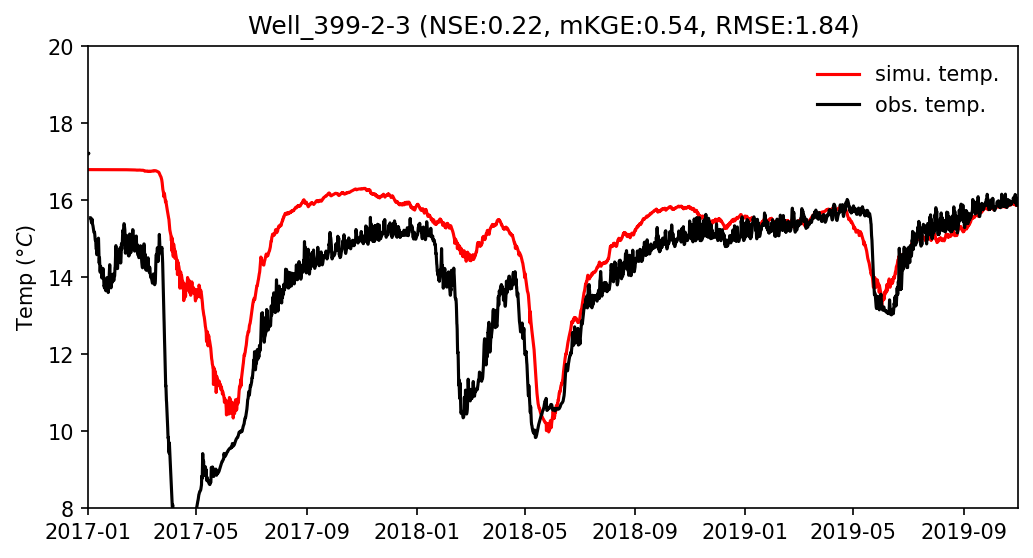

In [23]:
fig, isimu_df, iobs_df = plot_well_temp(iwell = 'Well_399-2-3', smooth_window='6H', flux_average=True, return_df=True)

### batch plot

In [ ]:
# for iwell in selected_obs_wells:
#     # fig = plot_well_temp(iwell)   
#     try:
#         fig = plot_well_temp(iwell, flux_average=True)
#     except:
#         pass
    
#     fig.savefig(figure_dir + f"{case_name}simu_obs_temp/" + iwell + '_2019.jpg', dpi=300)
#     plt.close(fig)

#### all in one

In [ ]:
well_list = [ 'Well_399-2-2','Well_399-1-16A','Well_399-1-21A','Well_399-1-7','Well_399-2-32','Well_399-2-3','Well_399-2-1']

In [ ]:
fig, axes = plt.subplots(4, 2, figsize = (12, 24))

for iwell, ax in zip(well_list, axes.flatten()[:-1]):
#     iwell = 'Well_399-2-2'
    isimu_head = well_data_df[iwell, 'Temperature [C]'].copy()
#     isimu_head = (isimu_head - P_atm) / rho / g_const
    isimu_head.dropna(axis = 1, inplace = True)

#     for i in isimu_head.columns:
#         isimu_head.loc[:, i] = isimu_head.loc[:, i] + obs_pts_df.loc[i, 'coord_z']

    simu_time = np.array([date_origin + timedelta(hours=i) for i in isimu_head.index])

    isimu_head['DateTime'] = simu_time
    isimu_head.set_index('DateTime', inplace=True)

    iobs_head =  obs_data_df[obs_data_df['WellName'] == iwell.replace('Well_', '')].sort_values(by = ['DateTime'])
    iobs_head = iobs_head[iobs_head['DateTime'].notnull()]
    iobs_head.set_index('DateTime', drop = False, inplace = True)
    
    merged_df = pd.merge(isimu_head, iobs_head, right_on = iobs_head.index ,left_index = True)
    merged_df.dropna(subset=[f'{iwell}_1', "Temp"], inplace=True)
    # rmse = mean_squared_error(merged_df.loc[:, f'{iwell}_1'], merged_df.loc[:, 'Temp'])**0.5
#     fig, ax = plt.subplots(1,1, figsize=(6,6))
    ax.plot(merged_df.index, merged_df.loc[:, f'{iwell}_1'], 'r-')
    ax.plot(merged_df.index,merged_df.loc[:, 'Temp'], 'k-')
#     sns.scatterplot(data = merged_df, x = f'{iwell}_1', y = "Temp", ax = ax)
#     ax.plot([0, 1], [0, 1], color='red', transform=ax.transAxes)
    # ax.text(0.7, 0.92, 'RMSE = {0:.2f}'.format(rmse), fontweight= 'bold',
    #      fontsize = 16, color = 'k', transform = ax.transAxes)
    
    ax.set_ylim([8, 20])
#     ax.legend(['simu_head', 'obs_head'])
    ax.set_title(iwell, fontsize = 20)
    ax.set_ylabel('Observed temperature (${\degree}C$)', fontsize = 16)
    ax.set_xlabel('Simulated temperature (${\degree}C$)', fontsize = 16)
    ax.set_aspect('auto')
    

axes[-1, -1].axis('off')
fig.tight_layout()

In [97]:
fig.savefig(out_dir + 'scatterplots/temp_allinone.png', dpi=300)
plt.close(fig)

#### one2one plot

In [ ]:
well_list = [ 'Well_399-2-2','Well_399-1-16A','Well_399-1-21A','Well_399-1-7','Well_399-2-32','Well_399-2-3','Well_399-2-1']

In [ ]:
fig, axes = plt.subplots(2, 4, figsize = (24, 12))

for iwell, ax in zip(well_list, axes.flatten()[:-1]):
#     iwell = 'Well_399-2-2'
    isimu_head = well_data_df[iwell, 'Temperature [C]'].copy()
#     isimu_head = (isimu_head - P_atm) / rho / g_const
    isimu_head.dropna(axis = 1, inplace = True)

#     for i in isimu_head.columns:
#         isimu_head.loc[:, i] = isimu_head.loc[:, i] + obs_pts_df.loc[i, 'coord_z']

    simu_time = np.array([date_origin + timedelta(hours=i) for i in isimu_head.index])

    isimu_head['DateTime'] = simu_time
    isimu_head.set_index('DateTime', inplace=True)

    iobs_head =  obs_data_df[obs_data_df['WellName'] == iwell.replace('Well_', '')].sort_values(by = ['DateTime'])
    iobs_head = iobs_head[iobs_head['DateTime'].notnull()]
    iobs_head.set_index('DateTime', drop = False, inplace = True)
    
    merged_df = pd.merge(isimu_head, iobs_head, right_on = iobs_head.index ,left_index = True)
    merged_df.dropna(subset=[f'{iwell}_1', "Temp"], inplace=True)
    rmse = mean_squared_error(merged_df.loc[:, f'{iwell}_1'], merged_df.loc[:, 'Temp'])**0.5
#     fig, ax = plt.subplots(1,1, figsize=(6,6))

    sns.scatterplot(data = merged_df, x = f'{iwell}_1', y = "Temp", ax = ax)
    ax.plot([0, 1], [0, 1], color='red', transform=ax.transAxes)
    ax.text(0.05, 0.85, 'RMSE = {0:.2f}'.format(rmse), fontweight= 'bold',
         fontsize = 16, color = 'k', transform = ax.transAxes)
    
#     ax.set_ylim([0, 24])
#     ax.legend(['simu_head', 'obs_head'])
    ax.set_title(iwell, fontsize = 20)
    ax.set_ylabel('Observed temperature (${\degree}C$)', fontsize = 16)
    ax.set_xlabel('Simulated temperature (${\degree}C$)', fontsize = 16)
    ax.set_aspect('auto')
    

axes[-1, -1].axis('off')
fig.tight_layout()

In [89]:
fig.savefig(out_dir + 'scatterplots/wl_one2one.png', dpi=300)
plt.close(fig)

### thermistors

In [60]:
well_data_df = well_data_df_hete
# well_data_df = well_data_df_homo

In [8]:
piezometer_list = [i for i in well_data_df.columns.levels[0] if "Well_" not in i]

#### Dense Array

In [37]:
DA_wells = [i for i in piezometer_list if i.startswith('T')]

In [38]:
DA_T = pd.read_csv(fname_DA_T, na_values = ['NA', 'NAN'])
DA_T = utils.insertNA(DA_T, 'TIMESTAMP')
DA_T.set_index('TIMESTAMP', drop = False, inplace = True)

2026-08-18 03:49:29,429 - root - INFO: Found the highest frequency: 300.0 sec


In [39]:
def plot_DA_temp(iwell, smooth_window = None, flux_average = True, return_df = False, start_date = None, end_date = None):
    
    iwell_id = well_screen[well_screen['WellName'] == iwell]['Well_ID'].values[0]

    iobs_df = DA_T.loc[:, iwell_id.replace('(', '.').replace(')', '.')].copy()
    # use 6-hr smoothing for observationd data (5 min freq)
    if smooth_window is not None:
        iobs_df = iobs_df.resample(smooth_window).mean()
    iobs_df[iobs_df < 0] = np.nan
    # iobs_smooth = iobs_df.resample('6H', offset='3H').mean()
    isimu_df = well_data_df.loc[:, [(iwell,'Temperature [C]', 'flux_ave_temp')]].copy()
    
    # isimu_df = well_data_df[iwell,'Temperature [C]'].copy()
    # isimu_df = isimu_df.sort_index()
    
    simu_time = np.array([date_origin + timedelta(hours=i) for i in isimu_df.index])
    
    isimu_df['DateTime'] = pd.to_datetime(simu_time)
    isimu_df.set_index('DateTime', inplace=True)

    # get metrics
    metric, _ = utils.get_metrics(iobs_df.index, iobs_df.values, isimu_df.index, isimu_df.iloc[:, -1].values, 
                     metrics=['RMSE', 'R^2', 'bias'])
    print(metric)
    
    fig, ax = plt.subplots(1,1, figsize=(8,4))

    ax.plot(iobs_df.index,iobs_df.values, 'k-')
    if flux_average:
        ax.plot(simu_time, isimu_df.iloc[:, -1], 'r-')
    else:
        ax.plot(simu_time, isimu_df.iloc[:, 0], 'r-')
    #     ax11 = ax.twinx()


    #     ax.legend(['simu. temp.', 'obs. temp.'],loc=[0.31, 1.01], frameon = False)

    # ax.set_xlim([iobs_df.index[0], iobs_df.index[-1]])
    # ax.set_xlim(['04/01/2017', '07/01/2019'])
    if start_date is None:
        # start_date = simu_time[0]
        start_date = iobs_df.index[0]
    else:
        start_date = pd.to_datetime(start_date)
    if end_date is None:
        # end_date = simu_time[-1] 
        end_date = iobs_df.index[-1]
    else:
        end_date = pd.to_datetime(end_date)
    ax.set_xlim([start_date, end_date])
    
    ax.set_ylim([0, 24])
    ax.legend(['Obs. temp.', 'Simu. temp.'],loc='best', frameon = False)
    # ax.set_title(iwell, fontsize = 16)
    ax.set_title(f"{iwell} (RMSE: {metric['RMSE']:.2f}, R\u00B2: {metric['R^2']:.2f}, bias: {metric['bias']:.2f})", fontsize=16)
    ax.set_ylabel('Temperature $(^{\circ}C)$', fontsize=16)
    # ax.set_ylabel('Temp (${\degree}C$)')    
    
    if return_df:
        return fig, isimu_df, iobs_df
    else:
        return fig

{'RMSE': 2.9808056430368257, 'R^2': 0.43843392381720064, 'bias': -1.5996790645837071}


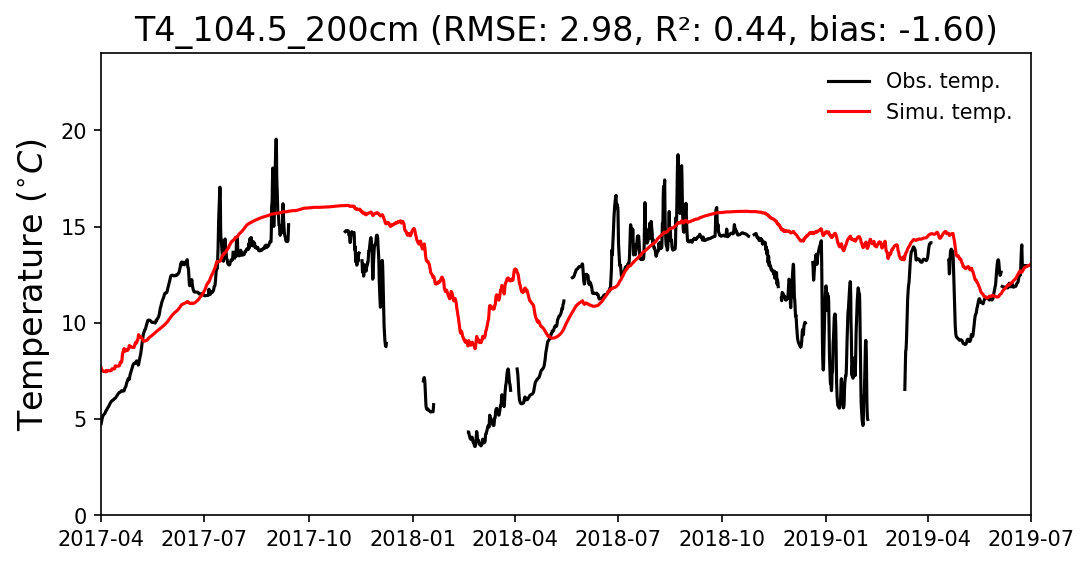

In [40]:
iwell = 'T4_104.5_200cm'
fig, isimu_df, iobs_df = plot_DA_temp(iwell = iwell, smooth_window='6H', flux_average=True, return_df=True, start_date="04/01/2017", end_date="07/01/2019")

{'RMSE': 1.8586778722709911, 'R^2': 0.6983445847287733, 'bias': -0.28055314670551457}


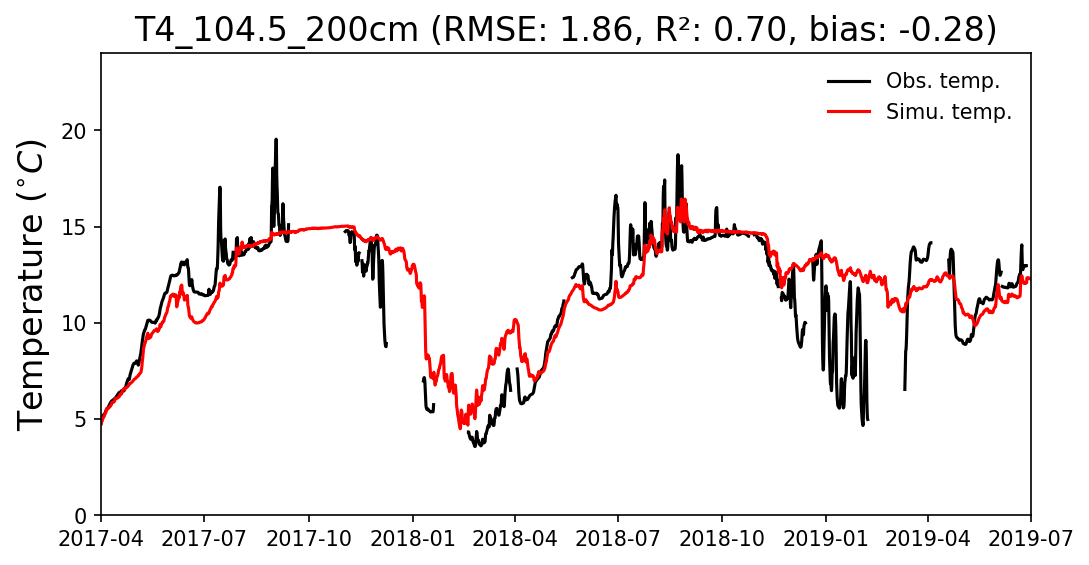

In [19]:
#hete case

In [39]:
fig.savefig(f"../figures/simu_obs_temp/hete_{iwell}.jpg", dpi=300)
plt.close(fig)  

Batch plot

In [26]:
for iwell in tqdm(DA_wells):
    fig = plot_DA_temp(iwell = iwell, smooth_window='6H', flux_average=True, start_date="04/01/2017", end_date="07/01/2019")
    # fig.savefig(f"../figures/simu_obs_temp/hete_{iwell}.jpg", dpi=300)
    fig.savefig(f"../figures/simu_obs_temp/homo_{iwell}.jpg", dpi=300)
    plt.close(fig)  
    

  0%|          | 0/50 [00:00<?, ?it/s]

{'RMSE': 2.709012919794054, 'R^2': 0.6552011207565968, 'bias': -0.9395575535004758}
{'RMSE': 2.4337053266989637, 'R^2': 0.6592469484432807, 'bias': -0.961950930590337}
{'RMSE': 2.169991334868779, 'R^2': 0.7108150978778826, 'bias': -1.321210758666216}
{'RMSE': 2.1870132623178207, 'R^2': 0.768044764396062, 'bias': -1.1819685802934976}
{'RMSE': 3.051262476597382, 'R^2': 0.46649907351120296, 'bias': -0.8815496074123507}
{'RMSE': 3.3494439999037278, 'R^2': 0.5215586631263397, 'bias': -0.7395430820895003}
{'RMSE': 3.1126244412941824, 'R^2': 0.4767658855570215, 'bias': -1.155341614902068}
{'RMSE': 2.2239453946868344, 'R^2': 0.7519534994330553, 'bias': -0.9563328352151644}
{'RMSE': 2.5766329517307693, 'R^2': 0.7033769372167934, 'bias': -1.057199338796641}
{'RMSE': 2.5079357746736575, 'R^2': 0.7151216031502009, 'bias': -1.1086353813129994}
{'RMSE': 3.350671769152196, 'R^2': 0.4344364838125147, 'bias': -0.6976325039935561}
{'RMSE': 3.59524267491405, 'R^2': 0.4966003710181902, 'bias': -0.79522376

#### iButton

Because of the small interval in some iButton screen, the simulated temp maybe from the same nearest cell. Need to increase model vertical resolution.

Note:
- The weird temp singnal after June is most likely due to iButton in the model location **rise above the water table**; need to refine the mesh resolution around the point observation

In [28]:
metadata = pd.read_csv(iButton_dir + 'iButton_b1_to_d6_Summary.csv')

In [29]:
all_files = glob.glob(iButton_dir + '*.csv')

In [30]:
all_files

['/global/cfs/cdirs/m1800/pin/github/HFR-thorne/data/riverbed_temp/iButton/d2.csv',
 '/global/cfs/cdirs/m1800/pin/github/HFR-thorne/data/riverbed_temp/iButton/c1.csv',
 '/global/cfs/cdirs/m1800/pin/github/HFR-thorne/data/riverbed_temp/iButton/d4.csv',
 '/global/cfs/cdirs/m1800/pin/github/HFR-thorne/data/riverbed_temp/iButton/c3.csv',
 '/global/cfs/cdirs/m1800/pin/github/HFR-thorne/data/riverbed_temp/iButton/b2.csv',
 '/global/cfs/cdirs/m1800/pin/github/HFR-thorne/data/riverbed_temp/iButton/c5.csv',
 '/global/cfs/cdirs/m1800/pin/github/HFR-thorne/data/riverbed_temp/iButton/b4.csv',
 '/global/cfs/cdirs/m1800/pin/github/HFR-thorne/data/riverbed_temp/iButton/b6.csv',
 '/global/cfs/cdirs/m1800/pin/github/HFR-thorne/data/riverbed_temp/iButton/d1.csv',
 '/global/cfs/cdirs/m1800/pin/github/HFR-thorne/data/riverbed_temp/iButton/iButton_b1_to_d6_Summary.csv',
 '/global/cfs/cdirs/m1800/pin/github/HFR-thorne/data/riverbed_temp/iButton/d3.csv',
 '/global/cfs/cdirs/m1800/pin/github/HFR-thorne/data/r

In [31]:
logger = 'b'
logger_files = [i for i in all_files if logger == i[-6] ]
logger_files = natsorted(logger_files)

In [32]:
iButton_wells = [i for i in piezometer_list if 'iButton' in i]

In [33]:
iButton_wells

['iButton_B2_28cm', 'iButton_B2_48cm', 'iButton_B2_88cm', 'iButton_B2_8cm']

In [34]:
def plot_iButton_temp(iwell, smooth_window = None, flux_average = True, return_df = False, start_date = None, end_date = None):

#     iwell = iButton_wells[0]
    iwell_id = well_screen[well_screen['WellName'] == iwell]['Well_ID'].values[0]
    iwell_name = metadata[metadata['Name'] == iwell_id.replace('iButton', 'Zhou')]['Represent Name'].values[0]

    ilogger = [i for i in logger_files if iwell_name in i][0]

    # fig, ax = plt.subplots(1,1, figsize=(8,6))

    # isimu_df = well_data_df[iwell,'Temperature [C]', 'flux_ave_temp'].copy()
    
    # labels = ['river temperature']
    # for ifile in logger_files[2:]:
    iobs_df = pd.read_csv(ilogger, skiprows=1, names=['datetime', 'temp'])
    iobs_df = insertNA(iobs_df, 'datetime')
    # # use 6-hr smoothing for observationd data (5 min freq)
    iobs_df['datetime'] = pd.to_datetime(iobs_df['datetime'])
    iobs_df.set_index('datetime', inplace=True)
    if smooth_window is not None:
        iobs_df = iobs_df.resample(smooth_window).mean()
    
    # print(iobs_df.head())

    #     df.rename(columns={'# Datetime': 'datetime'}, inplace = True)

    isimu_df = well_data_df.loc[:, [(iwell,'Temperature [C]', 'flux_ave_temp')]].copy()
    
    # iwell_id = well_screen[well_screen['WellName'] == iwell]['Well_ID'].values[0]
    
    simu_time = np.array([date_origin + timedelta(hours=i) for i in isimu_df.index])
    
    isimu_df['DateTime'] = pd.to_datetime(simu_time)
    isimu_df.set_index('DateTime', inplace=True)

    # if smooth_window is not None:
    #     # Apply rolling mean
    #     iobs_df = iobs_df.rolling(window=smooth_window).mean()

    # get metrics
    metric, _ = utils.get_metrics(iobs_df.index, iobs_df.iloc[:, 0].values, isimu_df.index, isimu_df.iloc[:, -1].values, 
                     metrics=['NSE', 'mKGE', 'RMSE'])
    print(metric)
    
    fig, ax = plt.subplots(1,1, figsize=(8,4))

    ax.plot(iobs_df.index,iobs_df.values, 'k-')
    if flux_average:
        ax.plot(simu_time, isimu_df.iloc[:, -1], 'r-')
    else:
        ax.plot(simu_time, isimu_df.iloc[:, 0], 'r-')

    if start_date is None:
        start_date = simu_time[0]
    if end_date is None:
        end_date = simu_time[-1]        
    
    ax.set_xlim([start_date, end_date])
    ax.set_ylim([0, 24])
    ax.legend(['obs. temp.', 'simu. temp.'],loc='best', frameon = False)
    # ax.set_title(iwell, fontsize = 16)
    ax.set_title(f"{iwell} (NSE:{metric['NSE']:.2f}, mKGE:{metric['mKGE']:.2f}, RMSE:{metric['RMSE']:.2f})", fontsize=16)
    ax.set_ylabel('Temperature $(^{\circ}C)$', fontsize=16)
    # ax.set_ylabel('Temp (${\degree}C$)')    
    
    if return_df:
        return fig, isimu_df, iobs_df
    else:
        return fig

{'NSE': -0.4442752882566936, 'mKGE': 0.4031190154019677, 'RMSE': 2.2967471909525523}


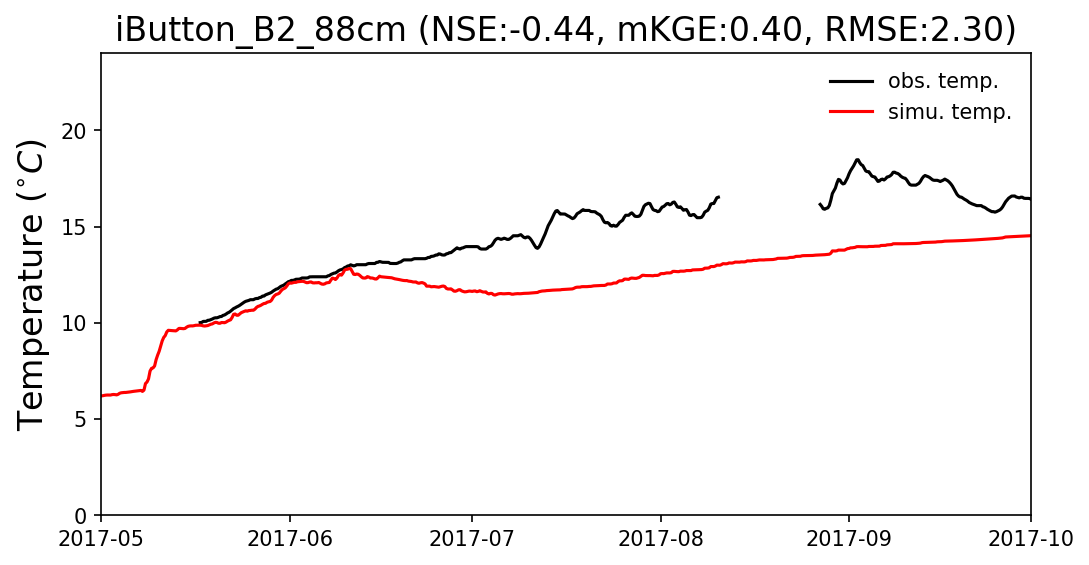

In [35]:
fig, isimu_df, iobs_df = plot_iButton_temp(iwell = 'iButton_B2_88cm', smooth_window='6H', flux_average=True, return_df=True, start_date="05/01/2017", end_date="10/01/2017")

{'NSE': -0.9483117656646671, 'mKGE': -0.09904397064612791, 'RMSE': 3.333637313146363}


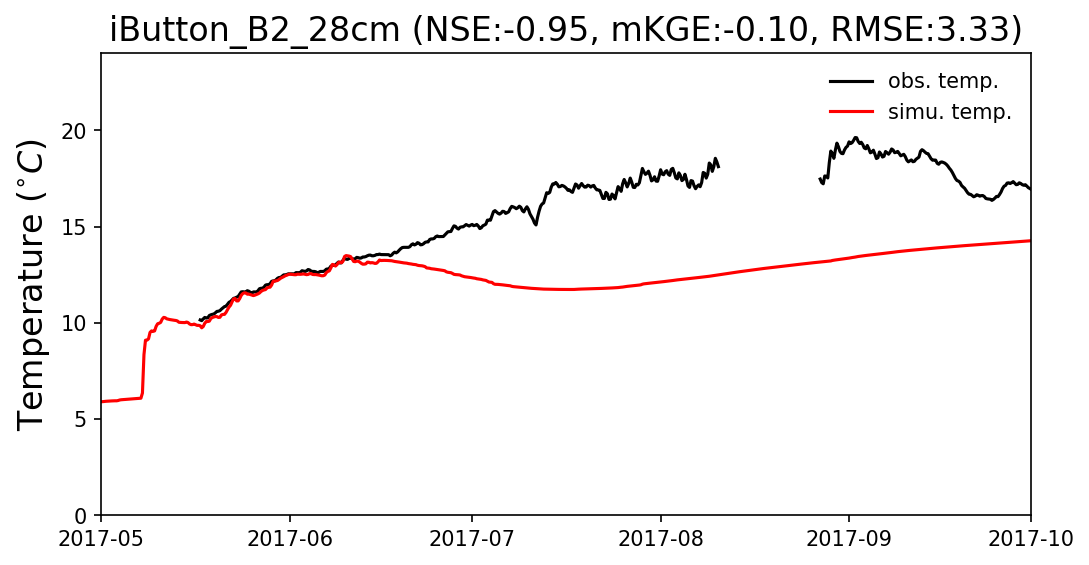

In [47]:
fig, isimu_df, iobs_df = plot_iButton_temp(iwell = 'iButton_B2_28cm', smooth_window='6H', flux_average=True, return_df=True, start_date="05/01/2017", end_date="10/01/2017")

{'NSE': -1.126888741739632, 'mKGE': -0.2933515734432779, 'RMSE': 3.9520086182205203}


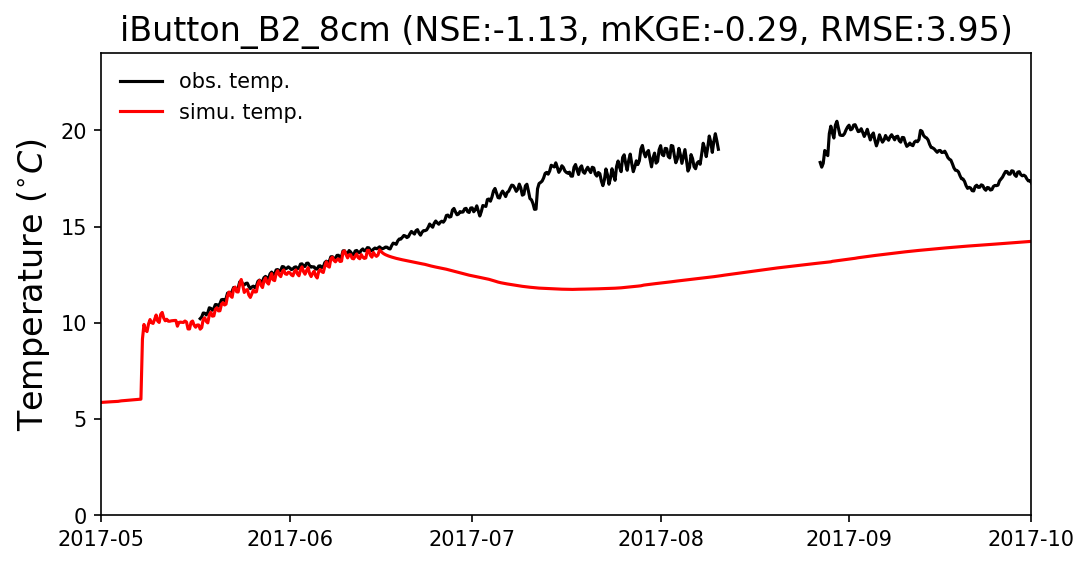

In [48]:
fig, isimu_df, iobs_df = plot_iButton_temp(iwell = 'iButton_B2_8cm', smooth_window='6H', flux_average=True, return_df=True,  start_date="05/01/2017", end_date="10/01/2017")

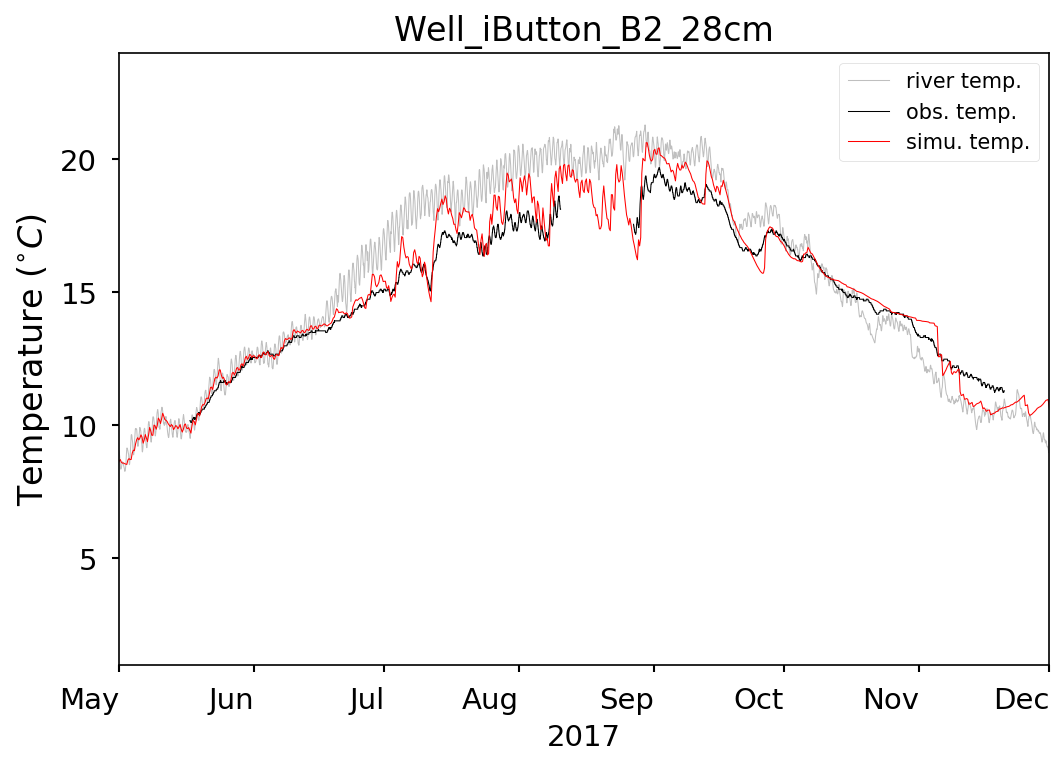

In [97]:
# is the plot generated from the 400m AT model?

#### RG3_T3

In [8]:
# RG3_T = pd.read_csv(fname_RG3_T, na_values = ['NAN'])
# RG3_T.dropna(subset=['time'], inplace=True)
# RG3_T = insertNA(RG3_T, 'time')
# RG3_T.set_index('time', drop=True, inplace=True)

RG3_T = pd.read_csv(fname_RG3_T, na_values = ['NAN'])
RG3_T.dropna(subset=['TIMESTAMP'], inplace=True)
RG3_T = utils.insertNA(RG3_T, 'TIMESTAMP')
RG3_T.set_index('TIMESTAMP', drop=True, inplace=True)

2026-08-20 16:04:28,069 - root - INFO: Found the highest frequency: 300.0 sec


In [9]:
RG3_T.columns = ['Record', '64cm', '24cm', '4cm',  '-16cm', '-26cm', '-46cm',]

In [10]:
RG3_smooth = RG3_T.resample('6H').mean()

<AxesSubplot:xlabel='TIMESTAMP'>

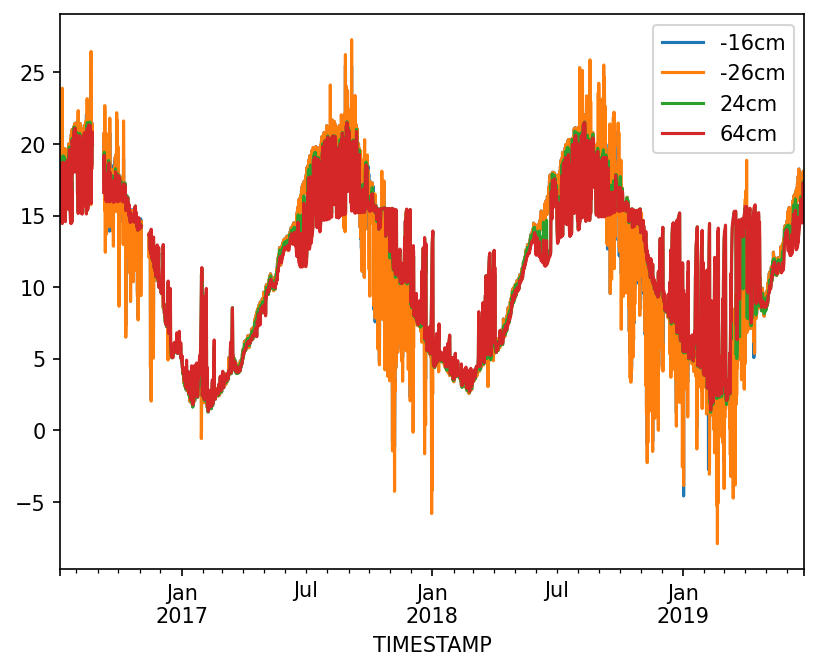

In [11]:
RG3_smooth[["-16cm", "-26cm", "24cm", "64cm"]].plot()

Plot MASS1 river temp. vs observed river temp at thermistor

In [73]:
river_temp_smooth = river_temp[['temp']].resample('6H').mean()

{'RMSE': 1.595404872843168, 'R^2': 0.9315626372724128, 'bias': -0.0681687265919649}


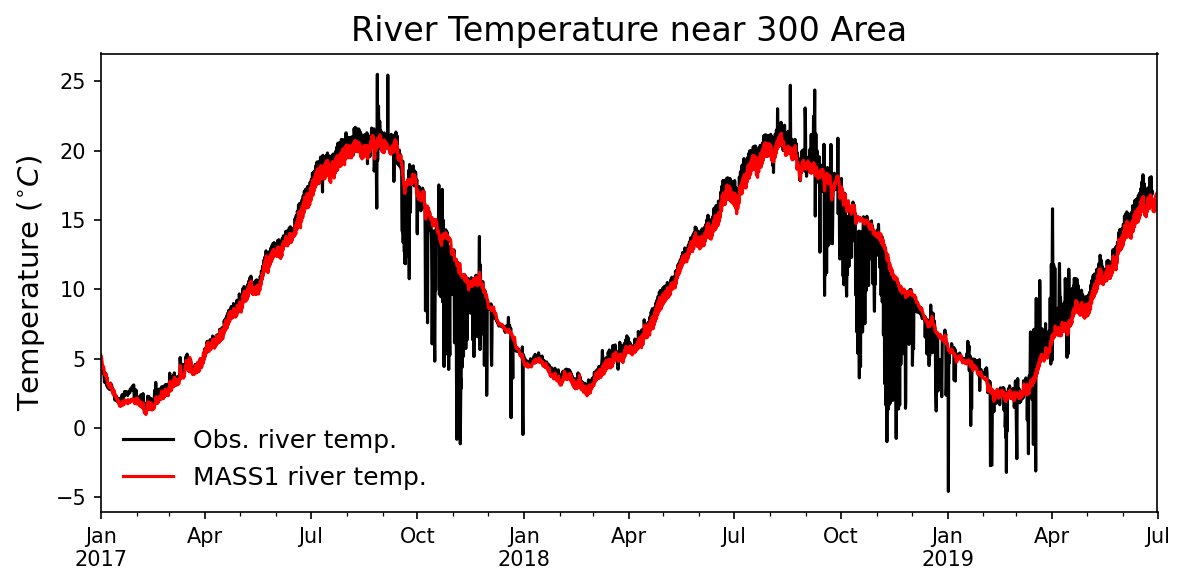

In [75]:
fig, ax = plt.subplots(1, 1, figsize=(8, 4))

RG3_smooth["-16cm"].plot(ax=ax, color='k', label="Obs. river temp.")
river_temp_smooth['temp'].plot(ax=ax, color='r', label="MASS1 river temp.")

ax.set_title("River Temperature near 300 Area", fontsize=16)
ax.set_xlabel("")
ax.set_ylabel(r"Temperature $(^{\circ}C)$", fontsize=14)
ax.set_xlim([pd.Timestamp("2017-01-01"), pd.Timestamp("2019-07-01")])
ax.legend(loc='best', frameon=False, fontsize=12)

# get metrics
metric, _ = utils.get_metrics(RG3_smooth["-16cm"].index, RG3_smooth["-16cm"].values, river_temp_smooth['temp'].index, river_temp_smooth['temp'].values,
                              metrics=['RMSE', 'R^2', 'bias'])
print(metric)

plt.tight_layout()
plt.show()

In [76]:
fig.savefig(f"../figures/river_temp_comp_300A.jpg", dpi=300)
plt.close(fig)

In [14]:
RG3_wells = [i for i in piezometer_list if 'RG3' in i]

In [15]:
RG3_wells

['RG3_T3_24cm', 'RG3_T3_64cm']

In [16]:
def plot_RG3_temp(iwell, depth=None, start_date=None, end_date=None, return_df=False):
    
    isimu_df = well_data_df.loc[:, [(iwell, 'Temperature [C]', 'flux_ave_temp')]].copy()
    simu_time = np.array([date_origin + timedelta(hours=i) for i in isimu_df.index])
    
    isimu_df['DateTime'] = pd.to_datetime(simu_time)
    isimu_df.set_index('DateTime', inplace=True)

    # set default dates
    if start_date is None:
        start_date = pd.Timestamp('2017-01-10')
    else:
        start_date = pd.to_datetime(start_date)
    if end_date is None:
        end_date = pd.Timestamp('2018-05-01')
    else:
        end_date = pd.to_datetime(end_date)

    # subset by date range
    isimu_df = isimu_df[(isimu_df.index >= start_date) & (isimu_df.index <= end_date)]

    if depth is None:
        depth = iwell.split('_')[-1]  # e.g., '24cm'
    iobs_df = RG3_smooth[depth]

    # subset iobs_df by date range
    iobs_df = iobs_df[(iobs_df.index >= start_date) & (iobs_df.index <= end_date)]

    # get metrics
    metric, _ = utils.get_metrics(iobs_df.index, iobs_df.values, isimu_df.index, isimu_df.iloc[:, -1].values,
                                  metrics=['RMSE', 'R^2', 'bias'])
    print(metric)
    
    fig, ax = plt.subplots(1, 1, figsize=(8, 4))
    ax.plot(iobs_df.index, iobs_df.values, 'k-')
    ax.plot(isimu_df.index, isimu_df.iloc[:, -1], 'r-')
    ax.set_ylabel(r'Temperature $(^{\circ}C)$', fontsize=16)
    ax.set_xlabel('')
    ax.set_xlim([start_date, end_date])
    ax.set_ylim([0, 24])
    ax.legend(['Obs. temp.', 'Simu. temp.'], loc='best', frameon=False)
    ax.set_title(f"{iwell} (RMSE: {metric['RMSE']:.2f}, R\u00B2: {metric['R^2']:.2f}, bias: {metric['bias']:.2f})",
                 fontsize=16)
    
    if return_df:
        return fig, isimu_df, iobs_df
    else:
        return fig

{'RMSE': 2.509061210775404, 'R^2': 0.7980914724476649, 'bias': -0.746278742294257}


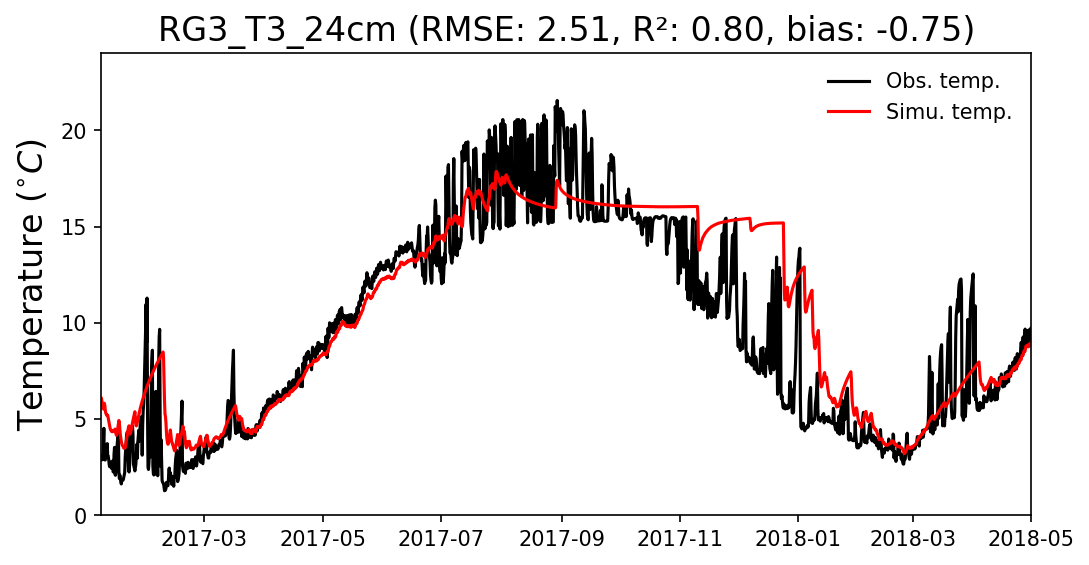

In [21]:
iwell='RG3_T3_24cm'
fig = plot_RG3_temp(iwell=iwell, start_date="01/07/2017", end_date="05/01/2018")

{'RMSE': 2.5661800818708755, 'R^2': 0.7039897810235698, 'bias': -0.1673073876057967}


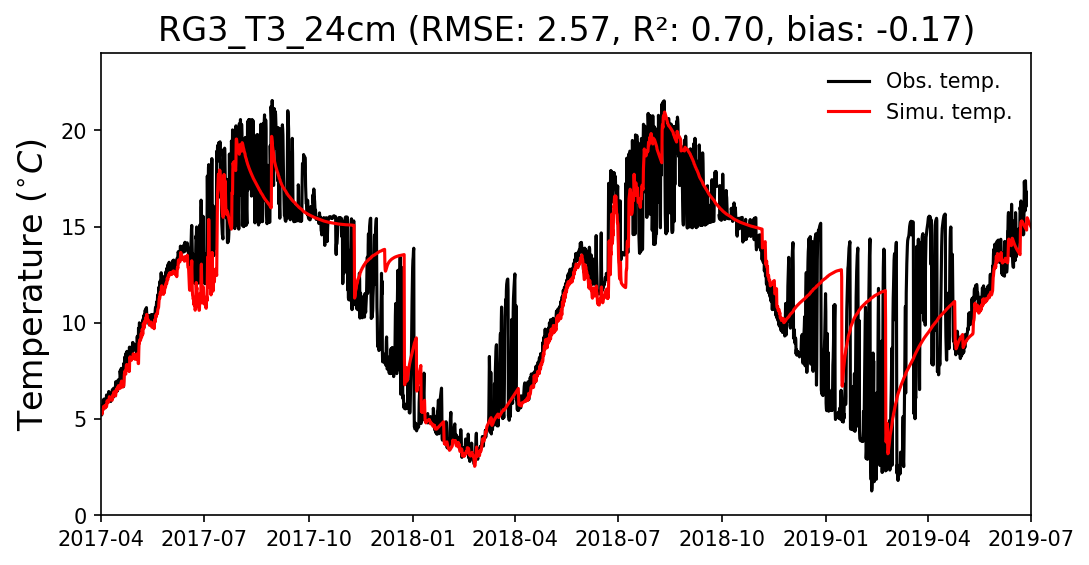

In [64]:
#hete

In [22]:
# fig.savefig(f"../figures/simu_obs_temp/hete_{iwell}.jpg", dpi=300)
fig.savefig(f"../figures/simu_obs_temp/homo_{iwell}.jpg", dpi=300)
plt.close(fig)

{'RMSE': 3.392488560972487, 'R^2': 0.646374773919432, 'bias': -1.4504899222196914}


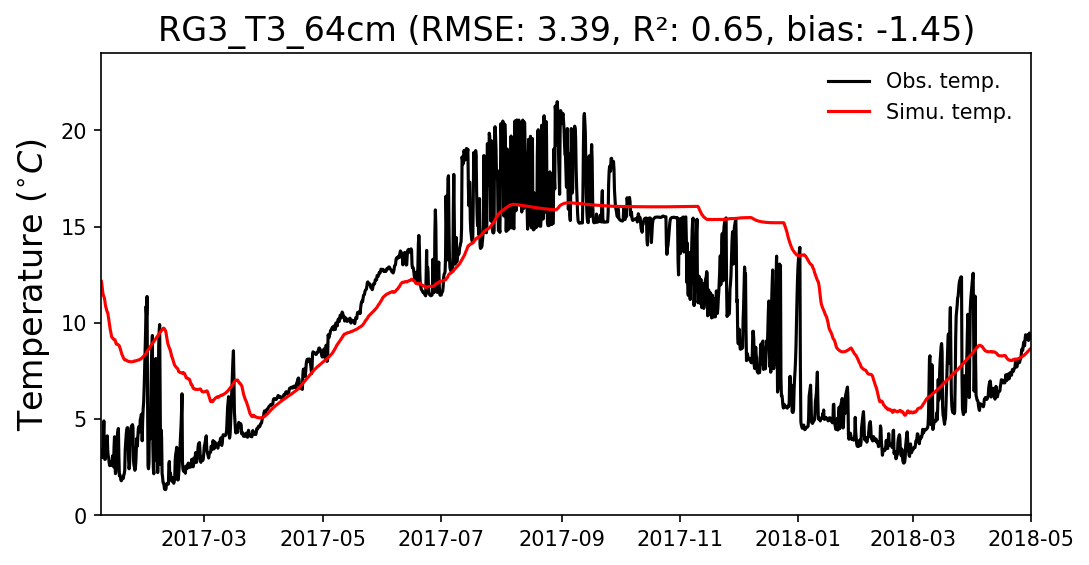

In [23]:
iwell='RG3_T3_64cm'
fig = plot_RG3_temp(iwell=iwell, start_date="01/07/2017", end_date="05/01/2018")

In [24]:
fig.savefig(f"../figures/simu_obs_temp/homo_{iwell}.jpg", dpi=300)
plt.close(fig)

#### 100H

- B and C thermal rods are clustered together
- In each location, three rods are placed at the same depths.
- Due to model resolution, only depth of 10 cm and 50 cm will be used for valication.

In [9]:
def plot_100H_temp(irod, simu_depth, obs_depth, iwell = None, start_date=None, end_date=None, return_df=False):
    original_iname = None  # <-- initialize before the if block
    if iwell is None:
        iname = mapping[irod] 
        original_iname = iname
        if iname in ['B', 'C']:
            iname = 'B_C'
        iwell = '100H_' + iname + '_' + simu_depth
    isimu_df = well_data_df.loc[:, [(iwell, 'Temperature [C]', 'flux_ave_temp')]].copy()
    simu_time = np.array([date_origin + timedelta(hours=i) for i in isimu_df.index])
    
    isimu_df['DateTime'] = pd.to_datetime(simu_time)
    isimu_df.set_index('DateTime', inplace=True)
    isimu_df = isimu_df[isimu_df.index >= '2017-01-10']

    irod_df = T_100H[T_100H['RodName'] == irod]
    irod_df.set_index('DateTime', inplace=True)
    irod_df = irod_df.resample('6H').mean()
    iobs_df = irod_df[obs_depth]
    # Check if iobs_df is empty
    if iobs_df.empty:
        raise ValueError(f"No observations found for rod '{irod}' at depth '{obs_depth}'.")
        
    # get metrics
    metric = None
    try:
        metric, _ = utils.get_metrics(iobs_df.index, iobs_df.values, isimu_df.index, isimu_df.iloc[:, -1].values,
                                  metrics=['RMSE', 'R^2', 'bias'])  # <-- changed
        print(metric)
    except Exception as e:
            print(f"Warning: Could not compute metrics for rod '{irod}' at depth '{obs_depth}'. Not enough overlapping points: {e}")
    
    
    fig, ax = plt.subplots(1, 1, figsize=(8, 4))
    ax.plot(iobs_df.index, iobs_df.values, 'k-')
    ax.plot(isimu_df.index, isimu_df.iloc[:, -1], 'r-')
    ax.set_ylabel(r'Temperature $(^{\circ}C)$', fontsize=16)  # <-- added r prefix
    ax.set_xlabel('')
    
    if start_date is None:
        start_date = pd.Timestamp('2019-05-29')
    if end_date is None:
        end_date = pd.Timestamp('2019-11-01')
    ax.set_xlim([start_date, end_date])
    ax.set_ylim([0, 30])
    ax.legend(['Obs. temp.', 'Simu. temp.'], loc='best', frameon=False)
    # iname = irod + '_' + depth

    if metric is not None:
        if original_iname not in ['B', 'C']:
            # iname = '100H_C'+ '_' + simu_depth
        # iwell = '100H_' + iname + '_' + simu_depth
            ax.set_title(f"{iwell} (RMSE: {metric['RMSE']:.2f}, R\u00B2: {metric['R^2']:.2f}, bias: {metric['bias']:.2f})",
                     fontsize=16)
        else:
            ax.set_title(f"100H_C_{simu_depth} (RMSE: {metric['RMSE']:.2f}, R\u00B2: {metric['R^2']:.2f}, bias: {metric['bias']:.2f})",
                     fontsize=16)
    else:
        ax.set_title(f"{iwell}", fontsize=16)
        
    # ax.set_title(f"{iwell} (RMSE: {metric['RMSE']:.2f}, R\u00B2: {metric['R^2']:.2f}, bias: {metric['bias']:.2f})",  # <-- changed
    #              fontsize=16)
    
    if return_df:
        return fig, isimu_df, iobs_df, iwell
    else:
        return fig, iwell

In [10]:
T_100H = pd.read_csv(fname_100H_data)

In [11]:
T_100H['DateTime'] = pd.to_datetime(T_100H['DateTime'])
# df['-5cm'] = pd.to_numeric(df['-5cm'])
# T_100H.set_index('DateTime', inplace=True)

In [12]:
logger_list = {'A':['rod507','rod508','rod601'], 
               'B':['rod504','rod505','rod605'], 
               'C':['rod511','rod512','rod515'],
               'E':['rod509','rod510','rod603'], 
               'F':['rod501','rod506','rod604'], 
               'G':['rod513','rod514','rod602']}
# only take a subset and pick one rod for each location since all three rods measure similar temperature
logger_subset = {
                # 'A':'rod507',
                # 'B':'rod605',
                'C':'rod515',
                'E':'rod509',
                'F':'rod506',
                'G':'rod602'}
# mapping = {v: k for k, v in logger_subset.items()}
mapping = {v: k for k, values in logger_list.items() for v in values}

In [13]:
depths= ['5cm','10cm','15cm','50cm','55cm']
# only these two depths have unique simulated time series due to cell discretization
# depths= ['10cm','50cm', '80cm', '100cm', '150cm'] 
# depths= ['15cm','55cm'] 
# all_rods = [rod for rods in logger_subset.values() for rod in rods]
sub_rods = list(logger_subset.values())

In [14]:
sub_rods

['rod515', 'rod509', 'rod506', 'rod602']

In [15]:
wells_100H = [i for i in well_data_df.columns.levels[0] if i.startswith('100H')]

In [16]:
wells_100H

['100H_A_100cm',
 '100H_A_10cm',
 '100H_A_150cm',
 '100H_A_15cm',
 '100H_A_50cm',
 '100H_A_55cm',
 '100H_A_5cm',
 '100H_A_80cm',
 '100H_A_offset_100cm',
 '100H_A_offset_150cm',
 '100H_A_offset_50cm',
 '100H_A_offset_55cm',
 '100H_A_offset_80cm',
 '100H_B_C_100cm',
 '100H_B_C_10cm',
 '100H_B_C_150cm',
 '100H_B_C_15cm',
 '100H_B_C_50cm',
 '100H_B_C_55cm',
 '100H_B_C_5cm',
 '100H_B_C_80cm',
 '100H_E_100cm',
 '100H_E_10cm',
 '100H_E_150cm',
 '100H_E_15cm',
 '100H_E_50cm',
 '100H_E_55cm',
 '100H_E_5cm',
 '100H_E_80cm',
 '100H_F_100cm',
 '100H_F_10cm',
 '100H_F_150cm',
 '100H_F_15cm',
 '100H_F_50cm',
 '100H_F_55cm',
 '100H_F_5cm',
 '100H_F_80cm',
 '100H_G_100cm',
 '100H_G_10cm',
 '100H_G_150cm',
 '100H_G_15cm',
 '100H_G_50cm',
 '100H_G_55cm',
 '100H_G_5cm',
 '100H_G_80cm',
 '100H_G_offset_100cm',
 '100H_G_offset_150cm',
 '100H_G_offset_80cm',
 '100H_iB2_offset_150cm',
 '100H_iC3_offset_100cm',
 '100H_iC3_offset_150cm',
 '100H_iC3_offset_80cm',
 '100H_iD4_offset_100cm',
 '100H_iD4_offset_150c

/tmp/ipykernel_974721/3908293709.py:18: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  irod_df = irod_df.resample('6H').mean()


{'RMSE': 3.6805397381482825, 'R^2': 0.6594131072284559, 'bias': 2.5118061704382892}


/tmp/ipykernel_974721/3908293709.py:18: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  irod_df = irod_df.resample('6H').mean()


{'RMSE': 3.379072694827402, 'R^2': 0.760017625238867, 'bias': 2.4268783314804185}


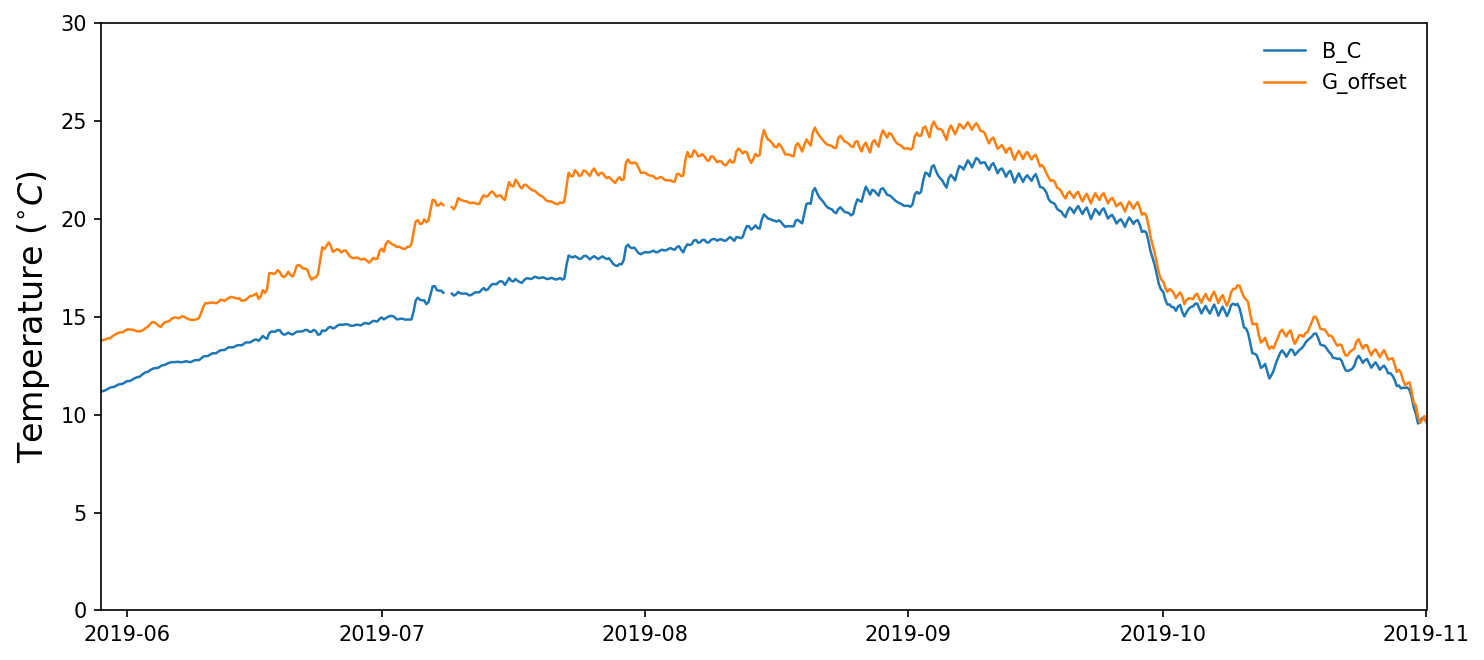

In [22]:
import matplotlib.pyplot as plt
import pandas as pd

specs = [
    dict(irod='rod515', simu_depth='55cm', obs_depth='55cm',
         iwell='100H_B_C_80cm',      label='B_C'),
    dict(irod='rod602', simu_depth='55cm', obs_depth='55cm',
         iwell='100H_G_offset_80cm', label='G_offset'),
]

START = pd.Timestamp('2019-05-29')
END   = pd.Timestamp('2019-11-01')

# harvest observations, discard the throwaway figures
results = []
for spec in specs:
    kwargs = {k: v for k, v in spec.items() if k != 'label'}
    fig_tmp, _, iobs_df, _ = plot_100H_temp(**kwargs, return_df=True)
    plt.close(fig_tmp)
    results.append((spec['label'], iobs_df))

# replot
fig, ax = plt.subplots(figsize=(10, 4.5))
colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

for i, (label, iobs_df) in enumerate(results):
    ax.plot(iobs_df.index, iobs_df.values, '-',
            color=colors[i % len(colors)], lw=1.2, label=label)

ax.set_xlim([START, END])
ax.set_ylim([0, 30])
ax.set_ylabel(r'Temperature $(^{\circ}C)$', fontsize=16)
ax.set_xlabel('')
ax.legend(loc='best', frameon=False, fontsize=10)
fig.tight_layout()
plt.show()

/tmp/ipykernel_974721/3908293709.py:18: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  irod_df = irod_df.resample('6H').mean()


{'RMSE': 2.6083149430637196, 'R^2': 0.7940128589638938, 'bias': 1.499757499118492}
{'RMSE': 3.379072694827402, 'R^2': 0.760017625238867, 'bias': 2.4268783314804185}


/tmp/ipykernel_974721/3908293709.py:18: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  irod_df = irod_df.resample('6H').mean()


(<Figure size 1200x600 with 1 Axes>, '100H_G_offset_80cm')

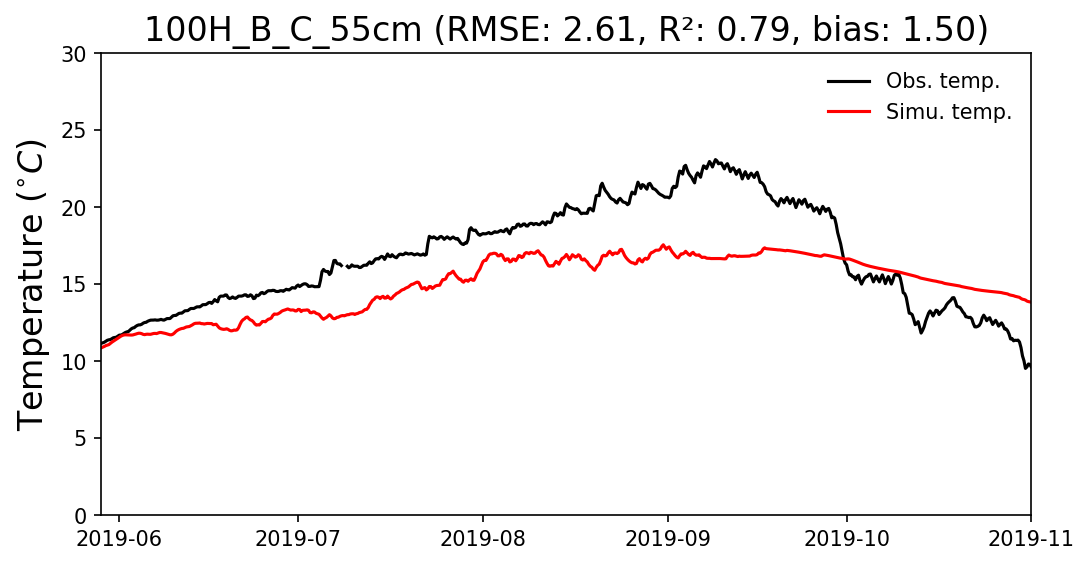

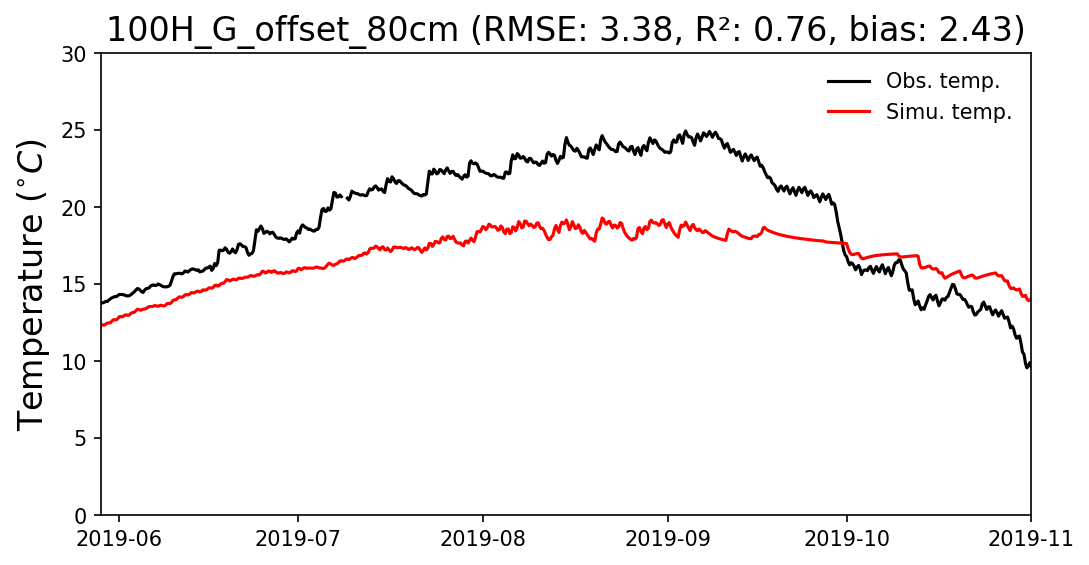

In [19]:
# irod = 'rod603'
irod = 'rod515'
iwell =  '100H_B_C_55cm'
plot_100H_temp(irod=irod, simu_depth="55cm", 
                     obs_depth="55cm", 
                     iwell =  iwell,
                    )

irod = 'rod602'
iwell =  '100H_G_offset_80cm'
plot_100H_temp(irod=irod, simu_depth="55cm", 
                     obs_depth="55cm", 
                     iwell =  iwell,
                    )

/tmp/ipykernel_794388/3908293709.py:18: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  irod_df = irod_df.resample('6H').mean()


{'RMSE': 3.379072694827402, 'R^2': 0.760017625238867, 'bias': 2.4268783314804185}


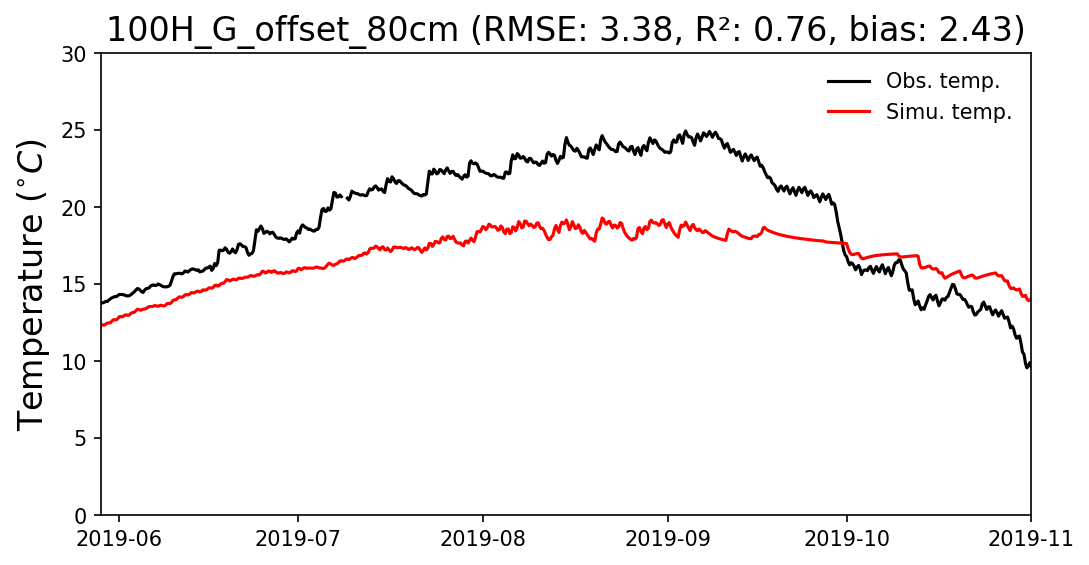

In [49]:
# irod = 'rod603'
irod = 'rod602'
iwell =  '100H_G_offset_80cm'
fig = plot_100H_temp(irod=irod, simu_depth="55cm", 
                     obs_depth="55cm", 
                     iwell =  iwell,
                    )

/tmp/ipykernel_341377/3908293709.py:18: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  irod_df = irod_df.resample('6H').mean()


{'RMSE': 3.268704421165467, 'R^2': 0.7734249301984234, 'bias': 2.3646701439012046}


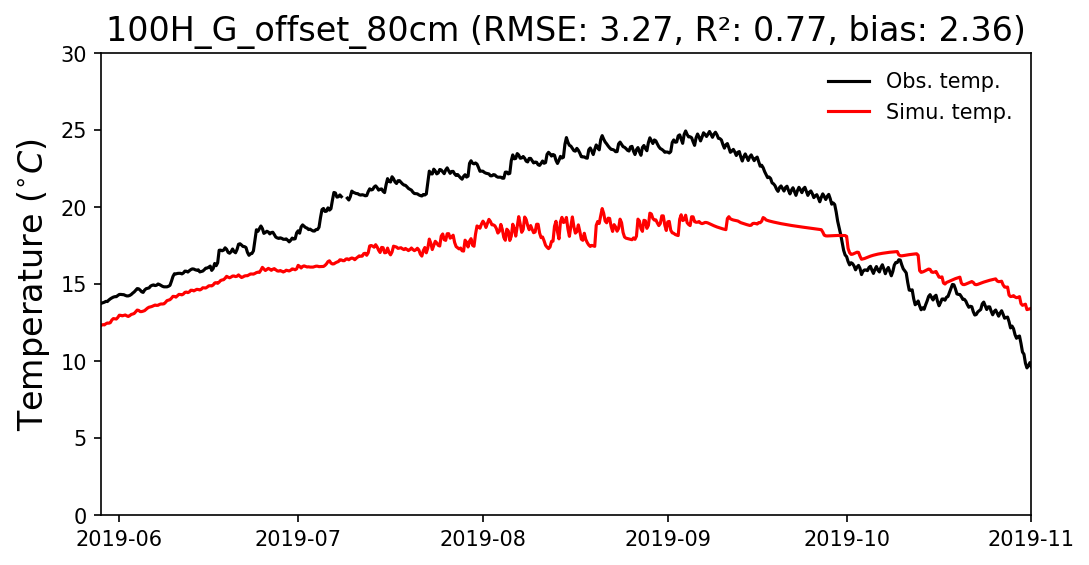

In [64]:
#hete

In [275]:
fig.savefig(f"../figures/simu_obs_temp/hete_{iwell}.jpg", dpi=300)
plt.close(fig)

Batch plot

In [50]:
for irod in sub_rods:
# for irod in ['rod515']:
    for idepth in depths:
        fig, iwell = plot_100H_temp(irod=irod, simu_depth= idepth, 
                         obs_depth= idepth,)
        # fig.savefig(f"../figures/simu_obs_temp/hete_{iwell}.jpg", dpi=300)
        fig.savefig(f"../figures/simu_obs_temp/homo_{iwell}.jpg", dpi=300)
        plt.close(fig)   

/tmp/ipykernel_794388/3908293709.py:18: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  irod_df = irod_df.resample('6H').mean()


{'RMSE': 2.7090069733927065, 'R^2': 0.5537091571707317, 'bias': 0.42801224616496025}


/tmp/ipykernel_794388/3908293709.py:18: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  irod_df = irod_df.resample('6H').mean()


{'RMSE': 2.333601449033666, 'R^2': 0.6633755800550077, 'bias': 0.7854769422201929}


/tmp/ipykernel_794388/3908293709.py:18: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  irod_df = irod_df.resample('6H').mean()


...

{'RMSE': 3.7023445450540473, 'R^2': 0.5282018143439852, 'bias': 1.6121413254460306}


/tmp/ipykernel_794388/3908293709.py:18: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  irod_df = irod_df.resample('6H').mean()


{'RMSE': 4.01630139155172, 'R^2': 0.5467520150627103, 'bias': 2.318685886109347}


/tmp/ipykernel_794388/3908293709.py:18: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  irod_df = irod_df.resample('6H').mean()


{'RMSE': 3.987901718496194, 'R^2': 0.5608773812953614, 'bias': 2.4037388194398606}


plot MASS1 river temp with 100H rod602 temp

In [95]:
river_temp = pd.read_csv(src_dir + '/data/temp_2017-2019_6h-smooth/Temp_River_159.txt', header = None, sep = " ", 
                          names= ['dt', 'temp'])
river_temp['datetime'] = [date_origin + timedelta(seconds = int(i)) for i in river_temp['dt'].values]
river_temp.set_index('datetime', drop = False, inplace = True)

In [96]:
river_temp_smooth = river_temp[['temp']].resample('6H').mean()

In [89]:
irod_df = T_100H[T_100H['RodName'] == 'rod602']
irod_df.set_index('DateTime', inplace=True)
irod_df = irod_df.resample('6H').mean()

/tmp/ipykernel_1221432/3694393180.py:3: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  irod_df = irod_df.resample('6H').mean()


{'RMSE': 5.550072300893342, 'R^2': 0.4181736736750484, 'bias': 0.2703070633415327}


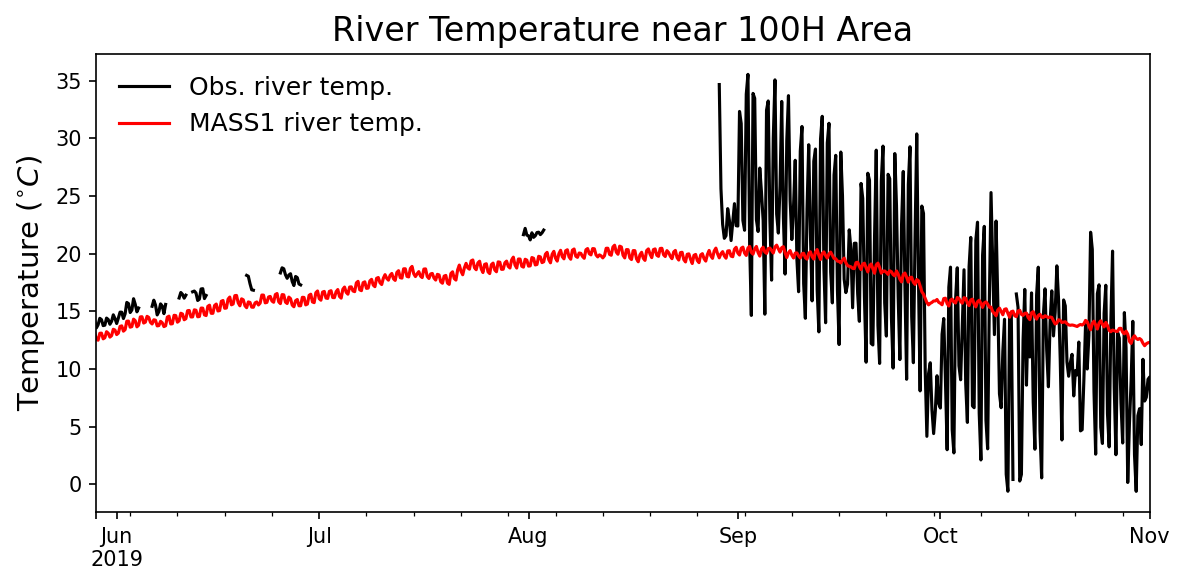

In [98]:
fig, ax = plt.subplots(1, 1, figsize=(8, 4))

irod_df["-5cm"].plot(ax=ax, color='k', label="Obs. river temp.")
river_temp_smooth['temp'].plot(ax=ax, color='r', label="MASS1 river temp.")

ax.set_title("River Temperature near 100H Area", fontsize=16)
ax.set_xlabel("")
ax.set_ylabel(r"Temperature $(^{\circ}C)$", fontsize=14)
# ax.set_xlim([pd.Timestamp("2017-01-01"), pd.Timestamp("2019-07-01")])
ax.set_xlim([pd.Timestamp('2019-05-29'), pd.Timestamp('2019-11-01')])
ax.legend(loc='best', frameon=False, fontsize=12)

# get metrics
metric, _ = utils.get_metrics(irod_df["-5cm"].index, irod_df["-5cm"].values, river_temp_smooth['temp'].index, river_temp_smooth['temp'].values,
                              metrics=['RMSE', 'R^2', 'bias'])
print(metric)

plt.tight_layout()
plt.show()

In [99]:
fig.savefig(f"../figures/river_temp_comp_100H.jpg", dpi=300)
plt.close(fig)

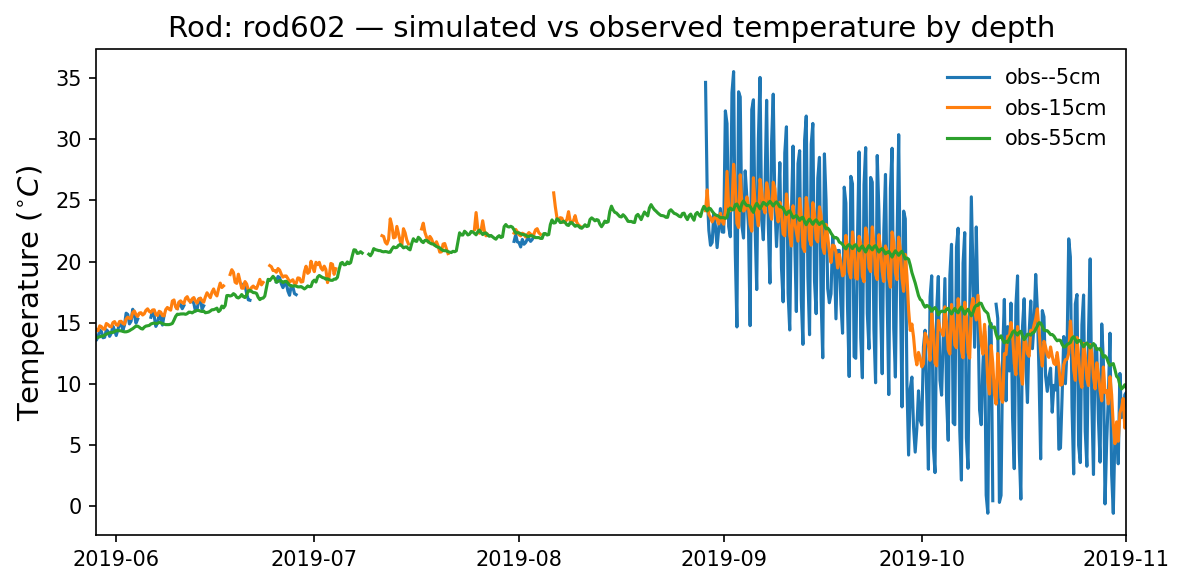

In [94]:
fig, ax = plt.subplots(1, 1, figsize=(8, 4))

# for depth in ['-5cm', '15cm','55cm']:
#     iwell = '100H_' + mapping[irod] + '_' + depth

#     isimu_df = well_data_df.loc[:, [(iwell, 'Temperature [C]', 'flux_ave_temp')]].copy()
#     simu_time = np.array([date_origin + timedelta(hours=i) for i in isimu_df.index])
#     isimu_df['DateTime'] = pd.to_datetime(simu_time)
#     isimu_df.set_index('DateTime', inplace=True)
#     isimu_df = isimu_df[isimu_df.index >= '2017-01-10']

#     ax.plot(isimu_df.index, isimu_df.iloc[:, -1], label=f'simu-{depth}')

for depth in ['-5cm', '15cm','55cm']:
    ax.plot(irod_df.index, irod_df[depth], label=f'obs-{depth}')  
# irod_df.plot(ax=ax)

ax.set_xlim([pd.Timestamp('2019-05-29'), pd.Timestamp('2019-11-01')])
ax.set_ylabel(r'Temperature $(^{\circ}C)$', fontsize=14)
ax.set_title(f"Rod: {irod} — simulated vs observed temperature by depth", fontsize=14)
ax.legend(loc='best', frameon=False)
plt.tight_layout()


## Hete vs homo cases

In [26]:
def plot_DA_temp_comparison(iwell, homo_well_data_df, hete_well_data_df, smooth_window=None, flux_average=True,
                            return_df=False, start_date=None, end_date=None):

    def get_simu_data(well_data_df):
        """Extract simu dataframe for a given well_data_df."""
        isimu_df = well_data_df.loc[:, [(iwell, 'Temperature [C]', 'flux_ave_temp')]].copy()
        simu_time = np.array([date_origin + timedelta(hours=i) for i in isimu_df.index])
        isimu_df['DateTime'] = pd.to_datetime(simu_time)
        isimu_df.set_index('DateTime', inplace=True)
        return isimu_df

    # --- load shared obs data ---
    iwell_id = well_screen[well_screen['WellName'] == iwell]['Well_ID'].values[0]
    iobs_df = DA_T.loc[:, iwell_id.replace('(', '.').replace(')', '.')].copy()
    if smooth_window is not None:
        iobs_df = iobs_df.resample(smooth_window).mean()
    iobs_df[iobs_df < 0] = np.nan

    # --- load simu data for both cases ---
    homo_simu = get_simu_data(homo_well_data_df)
    hete_simu = get_simu_data(hete_well_data_df)

    # --- plot all three lines in one panel ---
    col_idx = -1 if flux_average else 0

    fig, ax = plt.subplots(1, 1, figsize=(8, 4))

    ax.plot(iobs_df.index, iobs_df.values, color='gray', lw=1.0, ls='-',alpha=0.5)

    ax.plot(hete_simu.index, hete_simu.iloc[:, col_idx], color='steelblue', lw=1.5, ls='-')
    ax.plot(homo_simu.index, homo_simu.iloc[:, col_idx], color='tomato', lw=1.5, ls='--')

    ax.set_ylabel('Temperature $(^{\circ}C)$', fontsize=16)
    ax.set_ylim([0, 24])
    ax.legend(['Obs. temp.', 'Hete. simu.', 'Homo. simu.', ], loc='best', frameon=False)
    ax.set_title(iwell, fontsize=16)

    # --- x limits ---
    _start = start_date if start_date is not None else iobs_df.index[0]
    _end   = end_date   if end_date   is not None else iobs_df.index[-1]
    ax.set_xlim([_start, _end])

    fig.tight_layout()

    if return_df:
        return fig, (homo_simu, hete_simu), iobs_df
    else:
        return fig

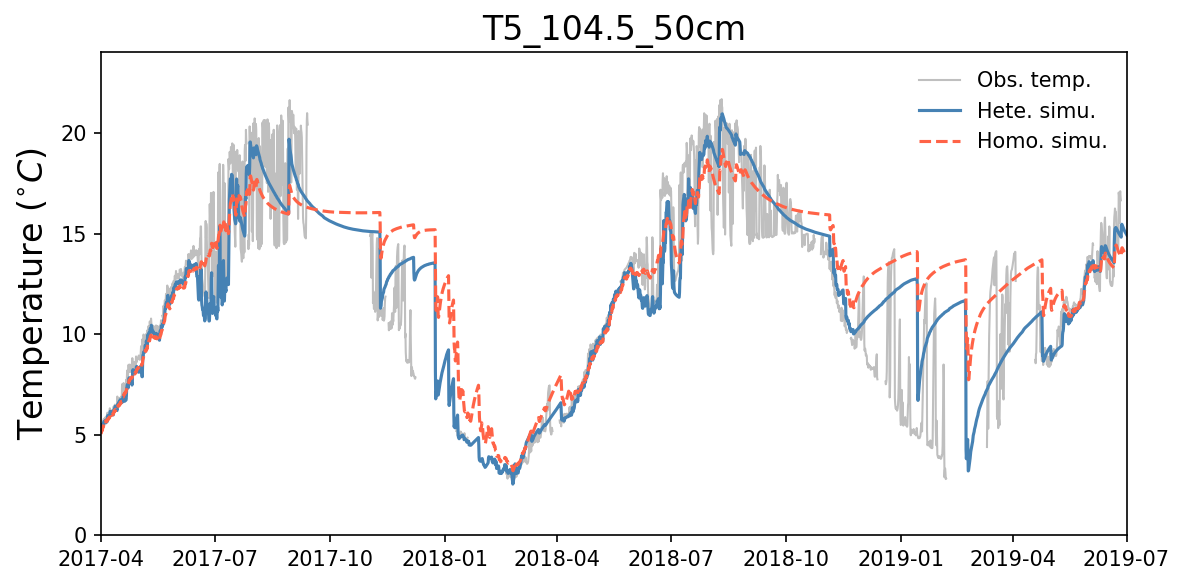

In [27]:
iwell = 'T5_104.5_50cm'
fig= plot_DA_temp_comparison(iwell , well_data_df_homo,  well_data_df_hete, smooth_window='6H', flux_average=True,  start_date="04/01/2017", end_date="07/01/2019")

In [28]:
for iwell in ['T5_104.5_50cm', 'T5_104.5_119cm', 'T5_104.5_203cm']:
    fig= plot_DA_temp_comparison(iwell , well_data_df_homo,  well_data_df_hete,
                                 smooth_window='6H', flux_average=True, 
                                 start_date="04/01/2017", end_date="07/01/2019")
    fig.savefig(f"../figures/simu_obs_temp/hete_vs_homo_{iwell}.jpg", dpi=300)
    plt.close(fig)  

In [29]:
for iwell in ['T5_104_46.5cm', 'T5_104_113.5cm', 'T5_104_153cm']:
    fig= plot_DA_temp_comparison(iwell , well_data_df_homo,  well_data_df_hete,
                                 smooth_window='6H', flux_average=True, 
                                 start_date="04/01/2017", end_date="07/01/2019")
    fig.savefig(f"../figures/simu_obs_temp/hete_vs_homo_{iwell}.jpg", dpi=300)
    plt.close(fig)  

### plot T5_104 hete

Plot simulated temp near the T5_104 thermistor at three depths

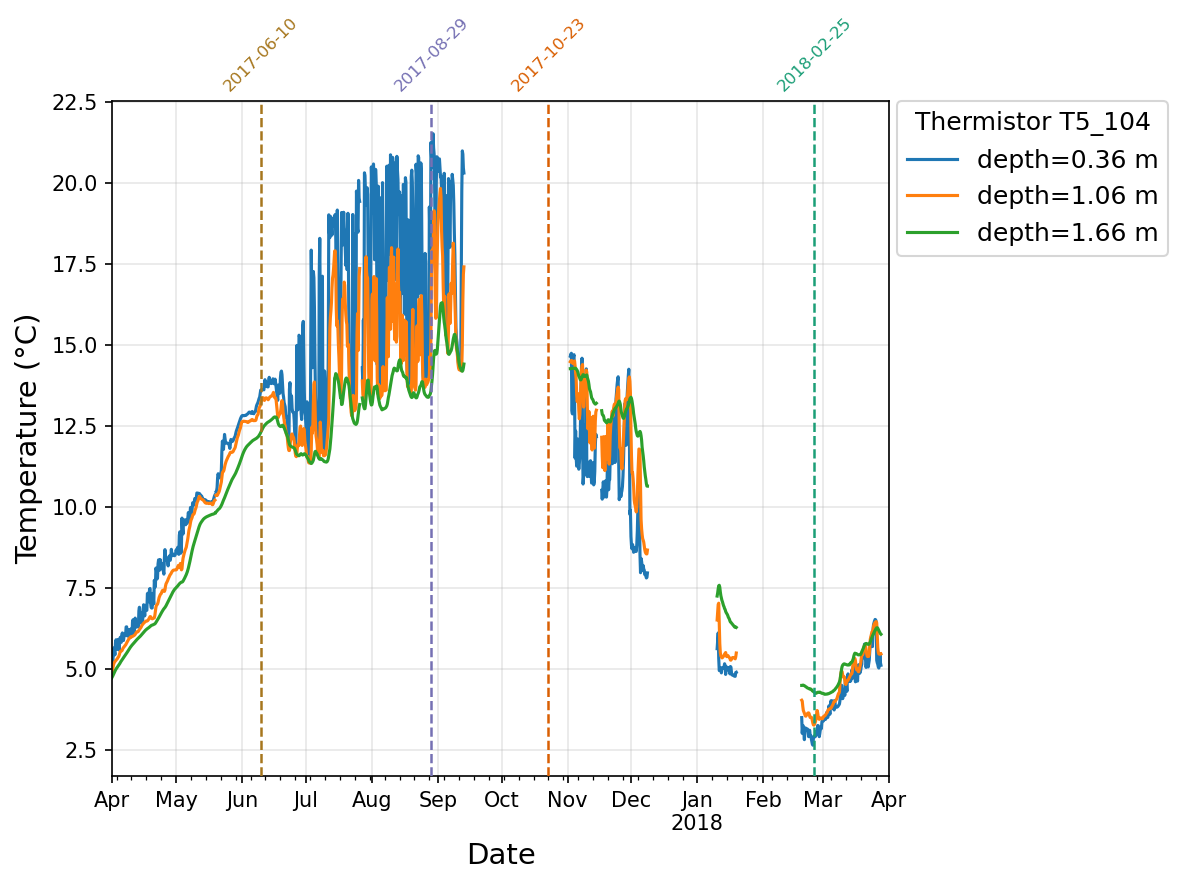

In [45]:
iwell_list = ['T5_104_46.5cm', 'T5_104_113.5cm', 'T5_104_153cm']

def get_simu_data(well_data_df, iwell):
    """Extract simu dataframe for a given well."""
    isimu_df = well_data_df.loc[:, [(iwell, 'Temperature [C]', 'flux_ave_temp')]].copy()
    simu_time = np.array([date_origin + timedelta(hours=i) for i in isimu_df.index])
    isimu_df['DateTime'] = pd.to_datetime(simu_time)
    isimu_df.set_index('DateTime', inplace=True)
    isimu_df.columns = [iwell]   # rename column to well name for clean legend
    return isimu_df

fig, ax = plt.subplots(1, 1, figsize=(8, 6))

depth_labels = ["depth=0.36 m", "depth=1.06 m", "depth=1.66 m"]

for iwell, label in zip(iwell_list, depth_labels):
    # isimu_df = get_simu_data(well_data_df_hete, iwell)
    # isimu_df.columns = [label]
    # isimu_df.plot(ax=ax, label=label)

    # --- load shared obs data ---
    iwell_id = well_screen[well_screen['WellName'] == iwell]['Well_ID'].values[0]
    iobs_df = DA_T.loc[:, iwell_id.replace('(', '.').replace(')', '.')].copy()
    # if smooth_window is not None:
    iobs_df = iobs_df.resample('6H').mean()
    iobs_df[iobs_df < 0] = np.nan

    iobs_df.plot(ax=ax, label = label)

ax.set_xlim([pd.to_datetime("04/01/2017"), pd.to_datetime("04/01/2018")])
ax.set_xlabel("Date", fontsize=14)
ax.set_ylabel("Temperature (°C)", fontsize=14)
# ax.set_title("Simulated Temperature at Wells", fontsize=16)

# Define timestamps to mark
itimes = [
    "2018-02-25",
    "2017-10-23",
    "2017-08-29",
    "2017-06-10"
]

# colors = ['green', 'orange', 'purple', 'brown']
colors = ['#1b9e77', '#d95f02', '#7570b3', '#a6761d']

for itime, color in zip(itimes, colors):
    dt = pd.Timestamp(itime)
    ax.axvline(dt, color=color, linestyle='--', linewidth=1.2, zorder=3)
    ax.text(dt, 1.01, itime,
            rotation=45, fontsize=8, color=color,
            va='bottom', ha='center',
            transform=ax.get_xaxis_transform(),
            clip_on=False)
fig.subplots_adjust(top=0.85)

ax.legend(fontsize=12, bbox_to_anchor=(1.01, 1), loc='upper left', 
          borderaxespad=0, title = "Thermistor T5_104", title_fontsize=12)
# ax.legend(fontsize=12)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [46]:
fig.savefig(f"../figures/observed_temp_at_depths_T5_104.jpg", dpi=300)
plt.close(fig)  

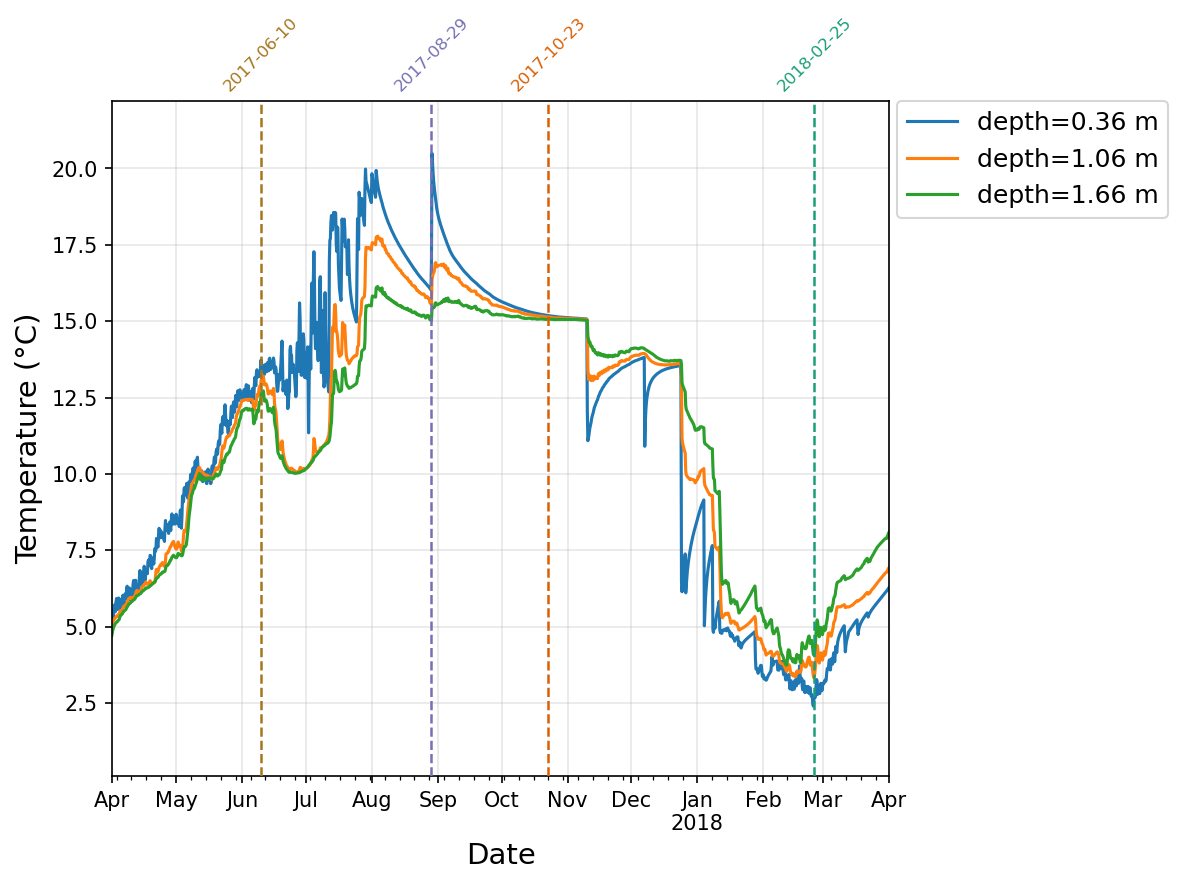

In [42]:
iwell_list = ['T5_104_46.5cm', 'T5_104_113.5cm', 'T5_104_153cm']

def get_simu_data(well_data_df, iwell):
    """Extract simu dataframe for a given well."""
    isimu_df = well_data_df.loc[:, [(iwell, 'Temperature [C]', 'flux_ave_temp')]].copy()
    simu_time = np.array([date_origin + timedelta(hours=i) for i in isimu_df.index])
    isimu_df['DateTime'] = pd.to_datetime(simu_time)
    isimu_df.set_index('DateTime', inplace=True)
    isimu_df.columns = [iwell]   # rename column to well name for clean legend
    return isimu_df

fig, ax = plt.subplots(1, 1, figsize=(8, 6))

depth_labels = ["depth=0.36 m", "depth=1.06 m", "depth=1.66 m"]

for iwell, label in zip(iwell_list, depth_labels):
    isimu_df = get_simu_data(well_data_df_hete, iwell)
    isimu_df.columns = [label]
    isimu_df.plot(ax=ax, label=label)

ax.set_xlim([pd.to_datetime("04/01/2017"), pd.to_datetime("04/01/2018")])
ax.set_xlabel("Date", fontsize=14)
ax.set_ylabel("Temperature (°C)", fontsize=14)
# ax.set_title("Simulated Temperature at Wells", fontsize=16)

# Define timestamps to mark
itimes = [
    "2018-02-25",
    "2017-10-23",
    "2017-08-29",
    "2017-06-10"
]

# colors = ['green', 'orange', 'purple', 'brown']
colors = ['#1b9e77', '#d95f02', '#7570b3', '#a6761d']

for itime, color in zip(itimes, colors):
    dt = pd.Timestamp(itime)
    ax.axvline(dt, color=color, linestyle='--', linewidth=1.2, zorder=3)
    ax.text(dt, 1.01, itime,
            rotation=45, fontsize=8, color=color,
            va='bottom', ha='center',
            transform=ax.get_xaxis_transform(),
            clip_on=False)
fig.subplots_adjust(top=0.85)

ax.legend(fontsize=12, bbox_to_anchor=(1.01, 1), loc='upper left', borderaxespad=0)
# ax.legend(fontsize=12)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [41]:
fig.savefig(f"../figures/simulated_temp_at_depths_near_DA.jpg", dpi=300)
plt.close(fig)  